In [307]:
# Librerias base
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time
import tracemalloc

# Librerías de Scikit-Learn para Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

In [308]:
# Cargare los datos de player y match
df_player_attr = pd.read_csv('../data/processed/clean/Player_Attributes_Clean.csv')
df_match = pd.read_csv('../data/processed/clean/Match_Clean.csv')

print(f"Forma de player atrributes: {df_player_attr.shape}")
print(f"Forma de match: {df_match.shape}")

Forma de player atrributes: (29739, 40)
Forma de match: (3040, 119)


In [309]:
# Se decide aislar a cada jugador por su mejor version
# Esto para evitar un sobreentrenamiento donde aprenda de varias versiones del jugador


# Se ordena 'overall_rating' de forma descendente y se queda con cada fila del primer jugador
df_peak_players = df_player_attr.sort_values(by="overall_rating", ascending=False).drop_duplicates(subset=['player_api_id'], keep='first').copy()

print(f"Total de jugadores únicos listos para clasificar: {len(df_peak_players)}")
display(df_peak_players[["player_api_id", "overall_rating", "date"]].head())


Total de jugadores únicos listos para clasificar: 1500


,player_api_id,overall_rating,date
18050,30981,94.0,2015-09-21
5768,30893,93.0,2015-09-25
11183,39989,92.0,2007-02-22
29349,39854,92.0,2011-08-30
2242,30955,91.0,2011-08-30


### Etiquetado de posiciones

Como la tabla `Match` no incluye directamente la posición de cada jugador, la estimamos a partir de su coordenada `Y`:

- **Portero (GK):** `Y = 1`
- **Defensa (DEF):** `2 <= Y <= 4`
- **Mediocampista (MID):** `4 < Y <= 8`
- **Delantero (FWD):** `Y > 8`

> **Limitación:** esta regla es una aproximación. La posición estimada puede variar según la formación y el rol táctico que el equipo use en cada partido.

In [310]:
# Voy a crear una lista para extraer atodos los jugadores local y visitante
posiciones_lista = []

# Creo una iteracion del 1 al 11 para sacar las coordenadas de los 22 jugadores en cancha
for i in range(1, 12):
    # Jugadores locales
    df_home = df_match[[f"home_player_{i}", f"home_player_Y{i}"]].copy()
    df_home.columns = ["player_api_id", "y_coord"]
    posiciones_lista.append(df_home)
    
    # Jugadores visitantes
    df_away = df_match[[f"away_player_{i}", f"away_player_Y{i}"]].copy()
    df_away.columns = ["player_api_id", "y_coord"]
    posiciones_lista.append(df_away)

# Voy a unir todo en un DataFrame, aun y si tiene nulos
df_todas_posiciones = pd.concat(posiciones_lista, ignore_index=True)

# Aislo y cuento  los nulos antes de borrarlos
df_posiciones_nulas = df_todas_posiciones[df_todas_posiciones.isna().any(axis=1)]
print(f"Total de posiciones/jugadores nulos en el registro: {len(df_posiciones_nulas)}")

# Muestro cuales son los jugadores
if not df_posiciones_nulas.empty:
    print("Muestra de los registros nulos (jugadores o coordenadas sin identificar):")
    display(df_posiciones_nulas.head())

# Al ver que ningun jugador tiene el id se crea un DataFrame limpio eliminando los jugadores vacios
df_posiciones_limpias = df_todas_posiciones.dropna().copy()

Total de posiciones/jugadores nulos en el registro: 399
Muestra de los registros nulos (jugadores o coordenadas sin identificar):


,player_api_id,y_coord
134,NaN,1.0
152,NaN,1.0
172,NaN,1.0
176,NaN,1.0
190,NaN,1.0


In [311]:
# 3. Traducimos las posiciones a estimados de posicion
def clasificar_posicion(y):
    if y == 1.0: return 'GK'         # Portero
    elif y > 1.0 and y <= 4.0: return 'DEF'  # Defensa
    elif y > 4.0 and y <= 8.0: return 'MID'  # Mediocampista
    else: return 'FWD'               # Delantero

# Se aplica la definicion
df_todas_posiciones['position'] = df_todas_posiciones['y_coord'].apply(clasificar_posicion)

# 4. En caso de tener varios roles en los partidos, se queda con la moda de posicion de cada jugador
df_target = df_todas_posiciones.groupby('player_api_id')['position'].agg(lambda x: x.mode()[0]).reset_index()

print(f" Se etiquetaron las posiciones de {len(df_target)} jugadores únicos.")
print("\nDistribución de clases para el modelo KNN:")
display(df_target['position'].value_counts())

 Se etiquetaron las posiciones de 1500 jugadores únicos.

Distribución de clases para el modelo KNN:


position
MID    647
DEF    509
FWD    231
GK     113
Name: count, dtype: int64

In [312]:
df_peak_players.head(5)
# df_target.head()

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,crossing,finishing,heading_accuracy,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
18050,102485,158023,30981,2015-09-21,94.0,95.0,left,80.0,93.0,71.0,...,90.0,74.0,13.0,23.0,21.0,6.0,11.0,15.0,14.0,8.0
5768,33332,20801,30893,2015-09-25,93.0,93.0,right,82.0,95.0,86.0,...,81.0,85.0,22.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0
11183,66758,1747,39989,2007-02-22,92.0,93.0,right,11.0,2.0,12.0,...,51.0,80.0,8.0,13.0,12.0,93.0,91.0,82.0,93.0,88.0
29349,180724,10535,39854,2011-08-30,92.0,92.0,right,85.0,70.0,51.0,...,97.0,75.0,55.0,62.0,61.0,5.0,15.0,12.0,5.0,9.0
2242,12790,41,30955,2011-08-30,91.0,93.0,right,85.0,74.0,54.0,...,93.0,65.0,57.0,57.0,56.0,6.0,13.0,6.0,13.0,7.0


### Exploración previa al modelo

Antes de entrenar el clasificador, revisaré brevemente las variables de entrada para entender sus tipos y distribuciones.

In [313]:
# Se une la version con mas rating con la df target
df_knn = pd.merge(df_peak_players, df_target, on='player_api_id', how='inner')

# Voy a excluir las columnas que no me sean de utilidad y el target
columnas_excluir = [
    'id', 'player_fifa_api_id', 'player_api_id', 'date', 
    'preferred_foot', 'position'
]
target = 'position'


In [314]:
# Como todas las variables me son de utilidad, las separo, usare un for para no tener que escribir todas a mano

features = [col for col in df_knn.columns if col not in columnas_excluir]

X = df_knn[features]
y = df_knn[target]



In [315]:
X

,overall_rating,potential,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,94.0,95.0,80.0,93.0,71.0,88.0,85.0,96.0,89.0,90.0,...,90.0,74.0,13.0,23.0,21.0,6.0,11.0,15.0,14.0,8.0
1,93.0,93.0,82.0,95.0,86.0,81.0,87.0,93.0,88.0,77.0,...,81.0,85.0,22.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0
2,92.0,93.0,11.0,2.0,12.0,28.0,9.0,9.0,10.0,80.0,...,51.0,80.0,8.0,13.0,12.0,93.0,91.0,82.0,93.0,88.0
3,92.0,92.0,85.0,70.0,51.0,97.0,69.0,83.0,85.0,87.0,...,97.0,75.0,55.0,62.0,61.0,5.0,15.0,12.0,5.0,9.0
4,91.0,93.0,85.0,74.0,54.0,95.0,74.0,91.0,80.0,65.0,...,93.0,65.0,57.0,57.0,56.0,6.0,13.0,6.0,13.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,57.0,63.0,30.0,61.0,59.0,38.0,44.0,56.0,32.0,28.0,...,45.0,62.0,25.0,25.0,25.0,11.0,12.0,9.0,13.0,9.0
1496,57.0,62.0,8.0,13.0,13.0,12.0,13.0,13.0,19.0,15.0,...,27.0,14.0,12.0,11.0,14.0,65.0,54.0,50.0,46.0,63.0
1497,56.0,70.0,34.0,56.0,55.0,42.0,54.0,45.0,63.0,32.0,...,63.0,56.0,23.0,23.0,50.0,18.0,23.0,40.0,23.0,23.0
1498,56.0,68.0,50.0,25.0,53.0,50.0,22.0,48.0,32.0,34.0,...,39.0,42.0,55.0,60.0,57.0,7.0,7.0,8.0,8.0,12.0


In [316]:
# Me voy a asegurar que todo sea numero
print("\nTipos de datos en la matriz X:")
display(X.dtypes.value_counts())

# Minimos y maximos de cada stat
print("\nEstadísticas descriptivas:")
display(X.describe().T[['min', 'mean', 'max']])


Tipos de datos en la matriz X:


float64    35
Name: count, dtype: int64


Estadísticas descriptivas:


,min,mean,max
overall_rating,54.0,75.454667,94.0
potential,58.0,78.825333,95.0
crossing,8.0,59.965333,93.0
finishing,2.0,54.600667,95.0
heading_accuracy,1.0,60.482000,95.0
short_passing,8.0,67.908000,97.0
volleys,3.0,51.424667,93.0
dribbling,3.0,63.439333,96.0
curve,7.0,58.549333,91.0
free_kick_accuracy,5.0,55.306667,94.0


Histogramas de nuestros datos


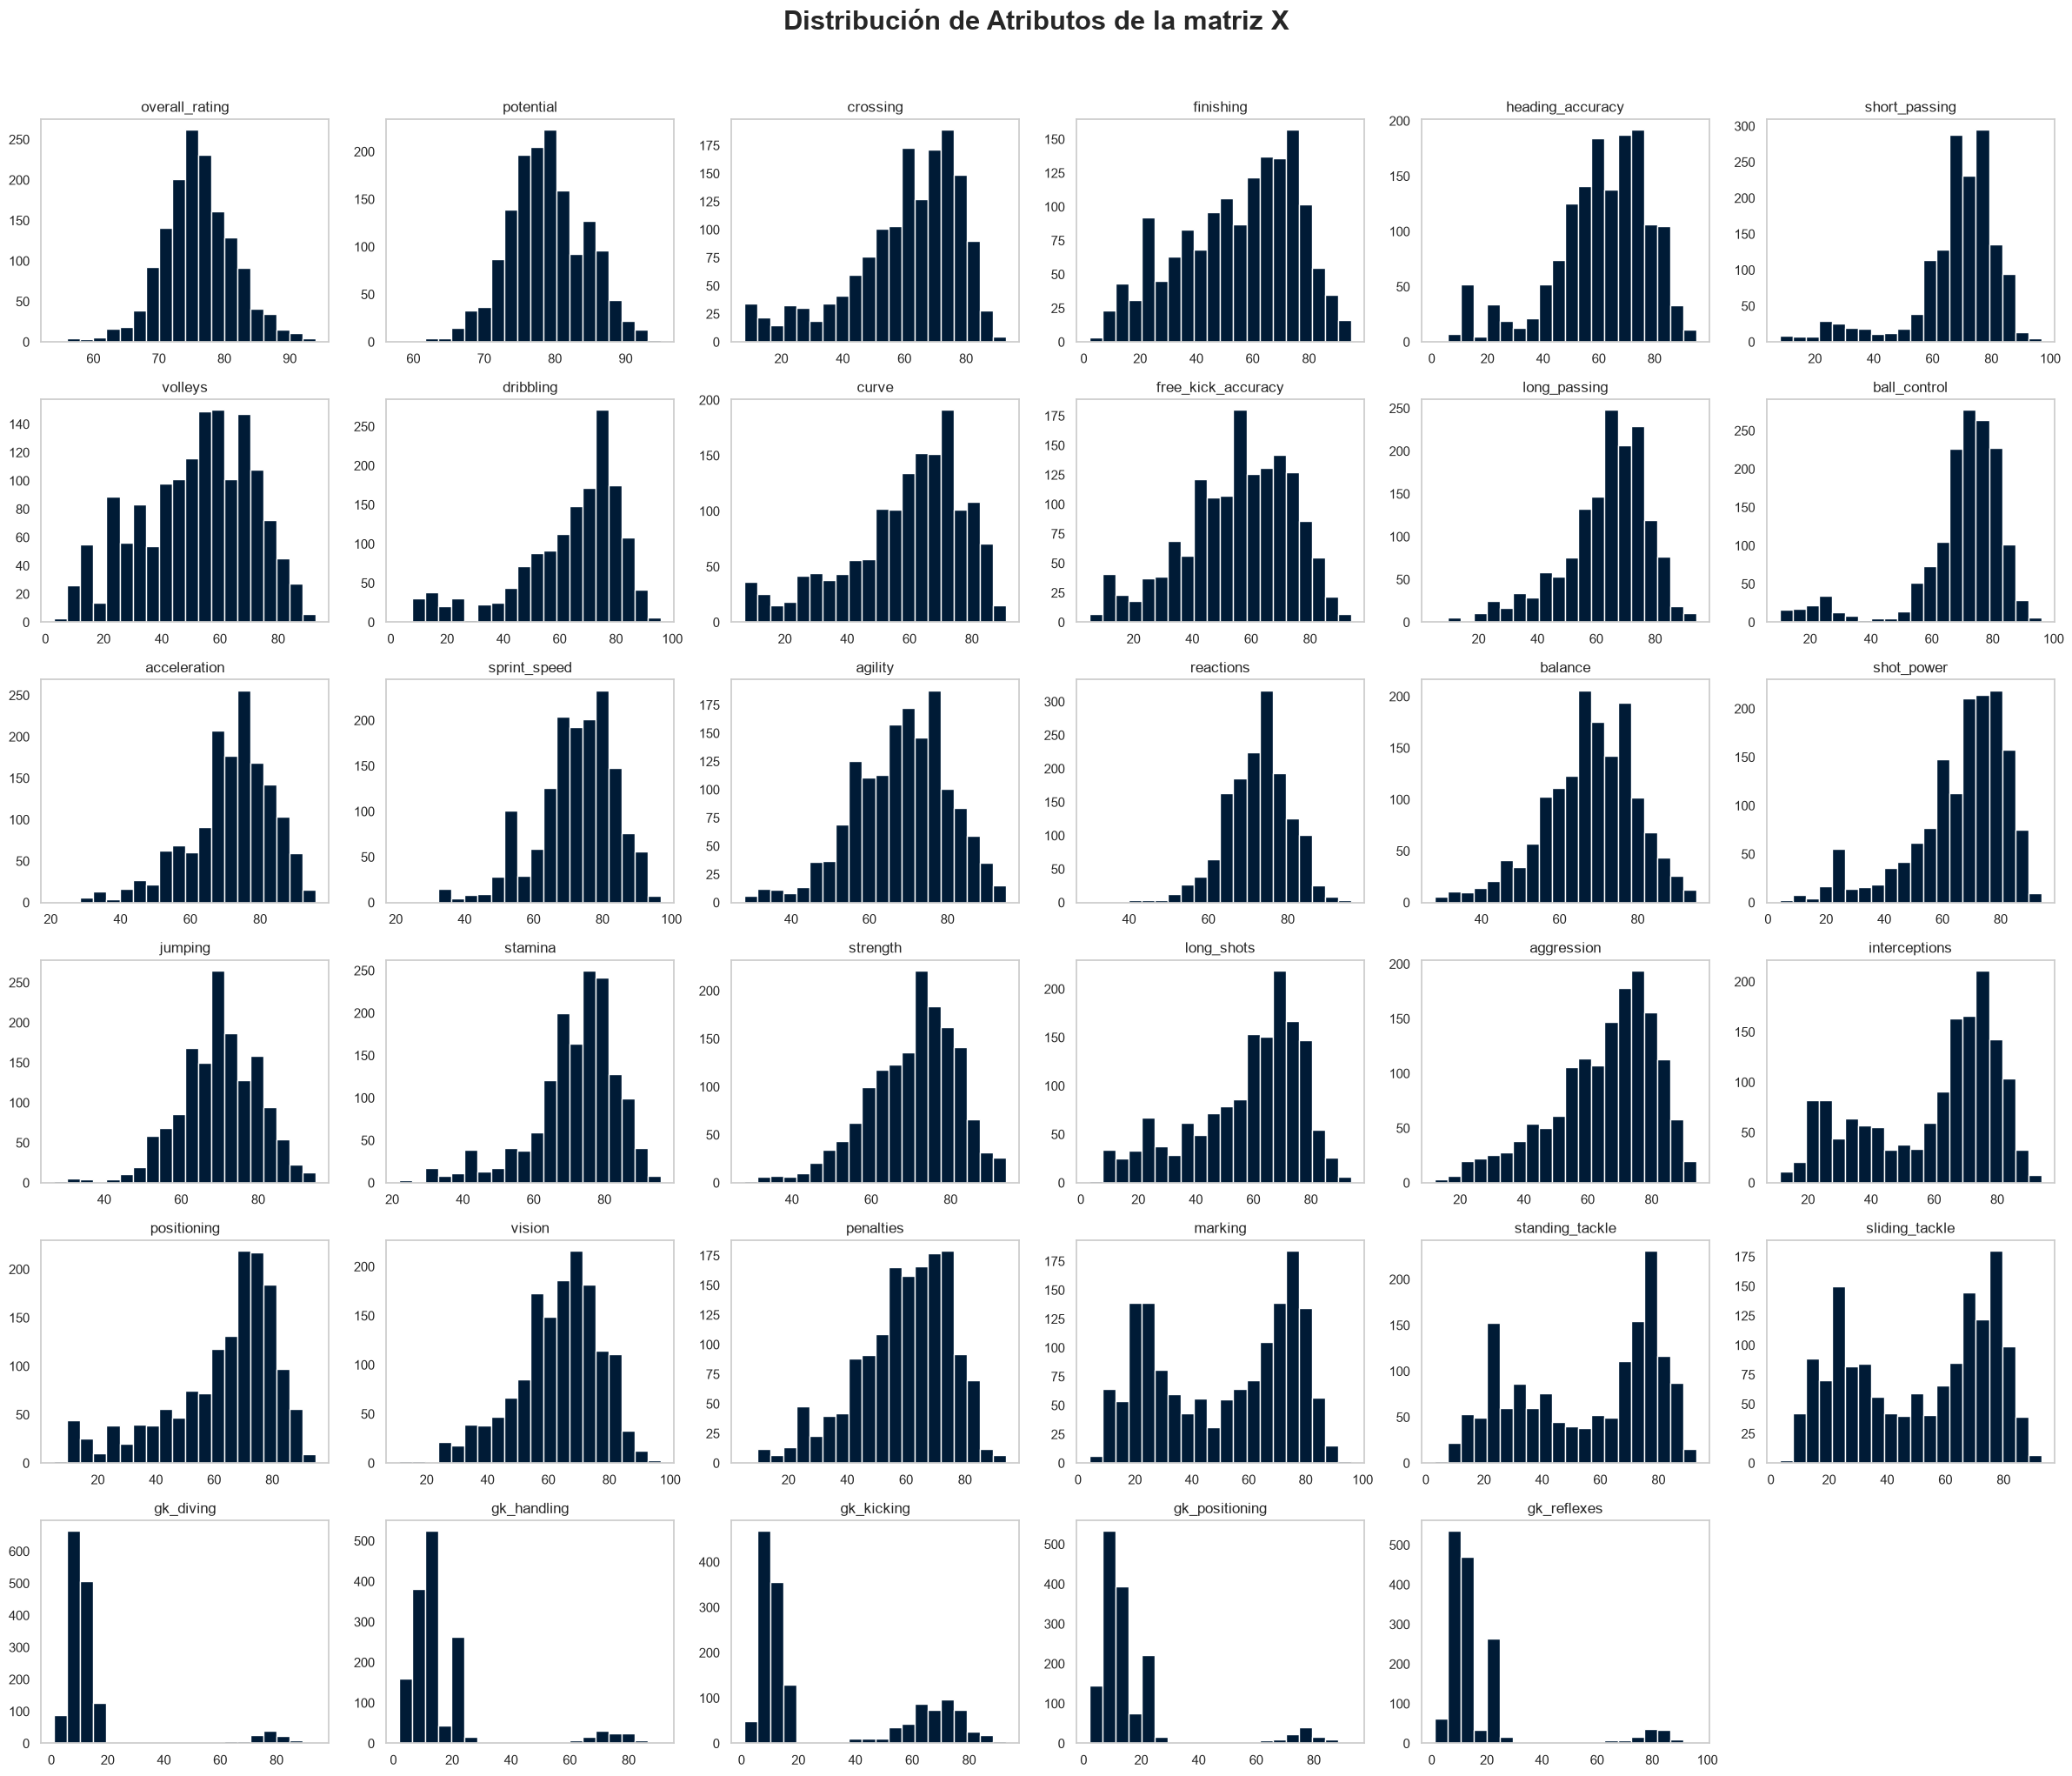

In [317]:
print("Histogramas de nuestros datos")

X.hist(bins=20, figsize=(24, 20), color='#001b36', edgecolor='white', grid=False)

plt.suptitle('Distribución de Atributos de la matriz X', fontsize=22, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Escalado de variables

Los histogramas muestran distribuciones distintas: algunas estadísticas de portero se concentran en ciertos valores, mientras que otras variables tienen una distribución más amplia. Como las variables están aproximadamente en una escala de 0 a 100, usaré `MinMaxScaler` para llevarlas a un rango común, adecuado para KNN.

In [318]:
# 1. Train-Test (80% Entrenamiento - 20% Prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) # stratify=y me asegura que la distribucion sea la misma por las posiciones

In [319]:
# Escalado con MinMaxScaler 
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [320]:
X_train_scaled

array([[0.425     , 0.48648649, 0.58823529, ..., 0.64130435, 0.23863636,
        0.22340426],
       [0.45      , 0.48648649, 0.68235294, ..., 0.10869565, 0.09090909,
        0.10638298],
       [0.6       , 0.64864865, 0.87058824, ..., 0.07608696, 0.125     ,
        0.06382979],
       ...,
       [0.45      , 0.37837838, 0.43529412, ..., 0.05434783, 0.07954545,
        0.09574468],
       [0.575     , 0.64864865, 0.78823529, ..., 0.15217391, 0.04545455,
        0.12765957],
       [0.55      , 0.54054054, 0.87058824, ..., 0.06521739, 0.13636364,
        0.11702128]], shape=(1200, 35))

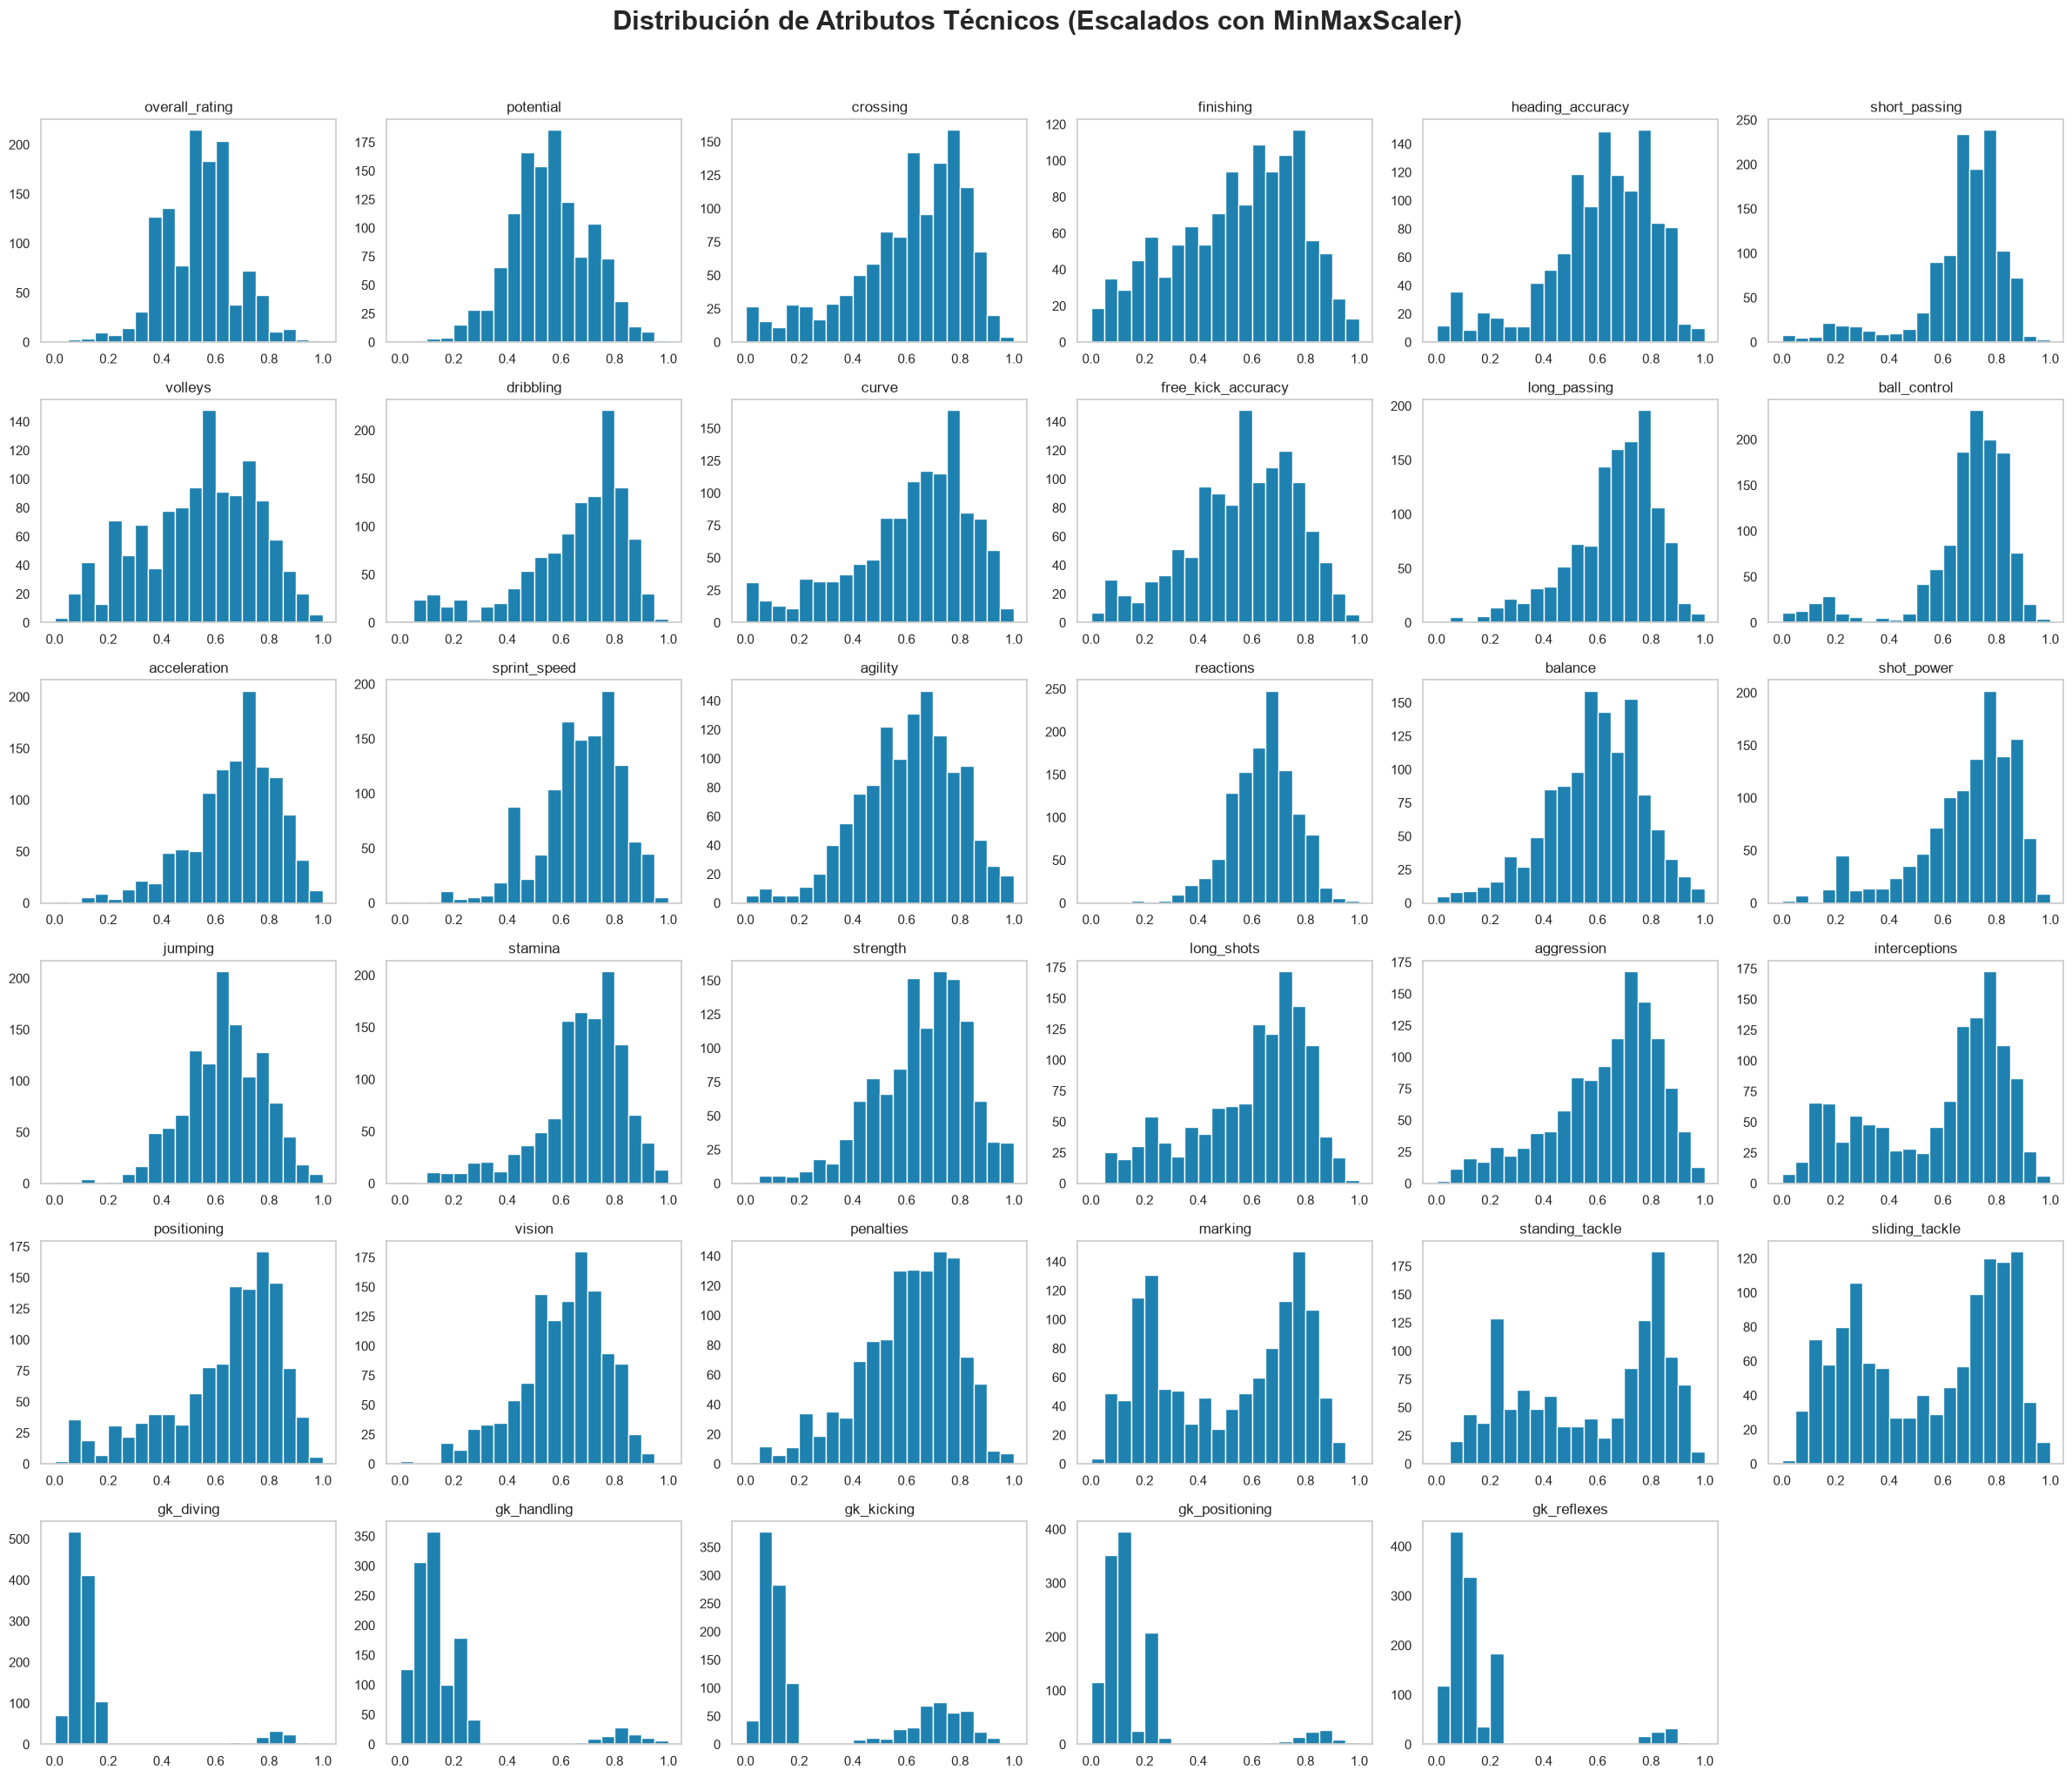


Comprobación de límites post-escalado:


,min,mean,max
overall_rating,0.0,0.534937,1.0
potential,0.0,0.560405,1.0
crossing,0.0,0.607902,1.0
finishing,0.0,0.540549,1.0
heading_accuracy,0.0,0.608456,1.0
short_passing,0.0,0.671498,1.0
volleys,0.0,0.538704,1.0
dribbling,0.0,0.650430,1.0
curve,0.0,0.614048,1.0
free_kick_accuracy,0.0,0.565712,1.0


In [321]:
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_train_scaled_df.hist(bins=20, figsize=(24, 20), color="#1e81b0", edgecolor="white", grid=False)

plt.suptitle("Distribución de Atributos Técnicos (Escalados con MinMaxScaler)", fontsize=22, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Comprobación matemática de los límites
print("\nComprobación de límites post-escalado:")
display(X_train_scaled_df.describe().T[["min", "mean", "max"]])

In [322]:
# en un rango de 1 a 30 hago la busqueda del k ideal
k_values = range(1, 30)
accuracies = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    y_pred_temp = knn_temp.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, y_pred_temp))

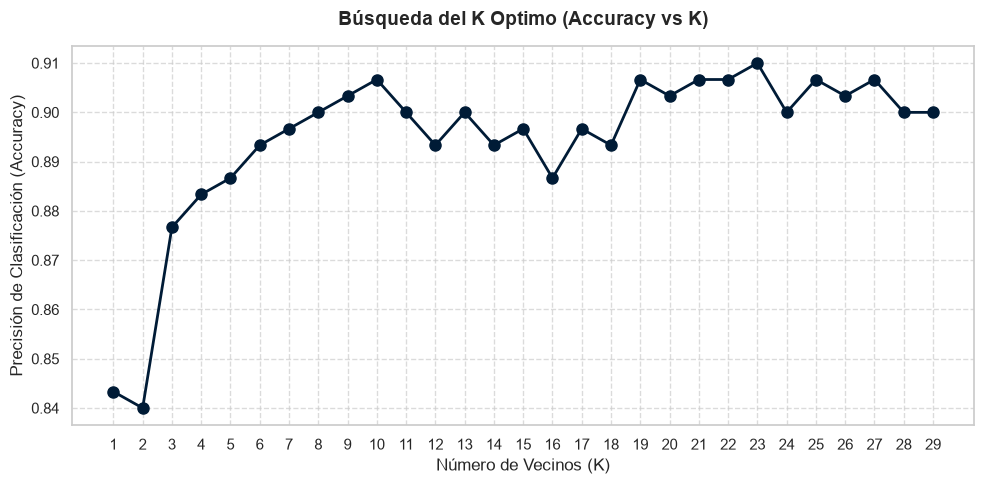

In [323]:
# Visualizo como sen los K ideales
plt.figure(figsize=(10, 5))
plt.plot(list(k_values), accuracies, marker='o', color='#001b36', linewidth=2, markersize=8)
plt.title('Búsqueda del K Optimo (Accuracy vs K)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Vecinos (K)', fontsize=12)
plt.ylabel('Precisión de Clasificación (Accuracy)', fontsize=12)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [324]:
# 5. Selección del mejor modelo
best_k = k_values[np.argmax(accuracies)]
max_acc = max(accuracies)

print(f"El mejor valor k optimo es {best_k}")

El mejor valor k optimo es 23



Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

         DEF       0.92      0.96      0.94       102
         FWD       0.86      0.80      0.83        46
          GK       1.00      1.00      1.00        23
         MID       0.90      0.89      0.89       129

    accuracy                           0.91       300
   macro avg       0.92      0.91      0.92       300
weighted avg       0.91      0.91      0.91       300



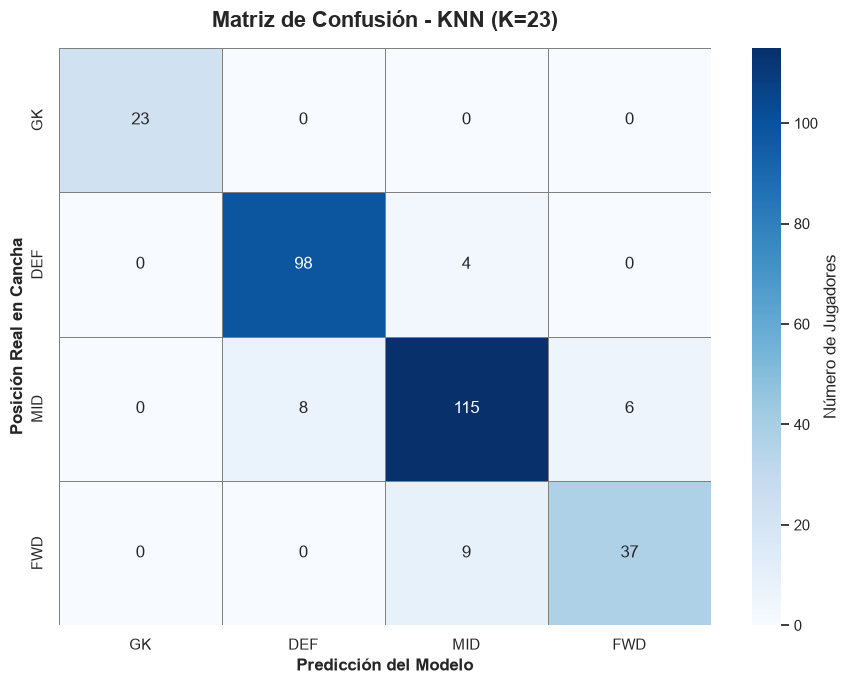

Tiempo total de ejecución (Fit + Predict): 0.0342 segundos
Consumo máximo de memoria RAM detectado: 0.6591 MB



In [325]:
tracemalloc.start()
start_time = time.time()

# Con el mejor K value entreno el modelo
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)

# Genero la prediccion con un set de test
y_pred_final = knn_final.predict(X_test_scaled)

current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
end_time = time.time()

# Precisión, Recall, F1-Score por posición
print("\nReporte de Clasificación Detallado:")
print(classification_report(y_test, y_pred_final))

# Visualización de la Matriz de Confusión
plt.figure(figsize=(9, 7))

# Definimos el orden de las posciones
orden_cancha = ['GK', 'DEF', 'MID', 'FWD'] 

cm = confusion_matrix(y_test, y_pred_final, labels=orden_cancha)

# Mapa de calor
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=orden_cancha, yticklabels=orden_cancha,
            linewidths=0.5, linecolor='gray', cbar_kws={'label': 'Número de Jugadores'})

plt.title(f'Matriz de Confusión - KNN (K={best_k})', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Predicción del Modelo', fontsize=12, fontweight='bold')
plt.ylabel('Posición Real en Cancha', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

tiempo_ejecucion = end_time - start_time
ram_usada_mb = peak_mem / (1024 * 1024) 

print(f"Tiempo total de ejecución (Fit + Predict): {tiempo_ejecucion:.4f} segundos")
print(f"Consumo máximo de memoria RAM detectado: {ram_usada_mb:.4f} MB\n")

In [326]:
# Llevare a cabo una validacion cruzada de 5 iteraciones para comprobar que tan efectivo es el modelo
from sklearn.model_selection import cross_val_score

# Iniciar medición
tracemalloc.start()
start_time = time.time()

# cross_val_score divide internamente el set, entrena 5 veces y evalúa
puntuaciones_cv = cross_val_score(knn_final, X_train_scaled, y_train, cv=5, scoring='accuracy')

# Capturar memoria y detener medición
current_mem, peak_mem = tracemalloc.get_traced_memory() # ¡ESTA LÍNEA FALTABA!
tracemalloc.stop()
end_time = time.time()

# Cálculos
tiempo_ejecucion = end_time - start_time
ram_usada_mb = peak_mem / (1024 * 1024) 

print(f"Accuracy de cada iteración: {np.round(puntuaciones_cv, 4)}")
print(f" Accuracy Promedio Real: {puntuaciones_cv.mean():.4f} ({(puntuaciones_cv.mean()*100):.2f}%)")
print(f" Desviación estándar (Margen de error): ±{puntuaciones_cv.std():.4f}")
print(f"Tiempo total de ejecución (5 iteraciones): {tiempo_ejecucion:.4f} segundos")
print(f"Consumo máximo de memoria RAM detectado: {ram_usada_mb:.4f} MB\n")

Accuracy de cada iteración: [0.8833 0.9    0.8542 0.8625 0.8458]
 Accuracy Promedio Real: 0.8692 (86.92%)
 Desviación estándar (Margen de error): ±0.0198
Tiempo total de ejecución (5 iteraciones): 0.2364 segundos
Consumo máximo de memoria RAM detectado: 0.7709 MB



### Modelo de referencia: Naive Bayes

Entrenaré `GaussianNB` como segundo clasificador y compararé sus resultados con KNN usando el mismo conjunto de prueba.

In [327]:
# Naive Bayes

tracemalloc.start()
start_time = time.time()

# Entrenamos el modelo Naive Bayes
# Nota: Naive Bayes no tiene hiperparámetros complejos que buscar, aprende directo de las probabilidades
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# Generar predicciones
y_pred_nb = nb_model.predict(X_test_scaled)

# Detengo la medicion
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
end_time = time.time()

# Cálculos de eficiencia
tiempo_ejecucion_nb = end_time - start_time
ram_usada_mb_nb = peak_mem / (1024 * 1024) 
acc_nb = accuracy_score(y_test, y_pred_nb)

print(f"Accuracy General (Naive Bayes): {acc_nb:.4f} ({(acc_nb*100):.2f}%)")
print(f"Tiempo total de ejecución: {tiempo_ejecucion_nb:.6f} segundos")
print(f"Consumo máximo de memoria RAM detectado: {ram_usada_mb_nb:.6f} MB\n")

print(" Reporte de Clasificación (Naive Bayes)")
print(classification_report(y_test, y_pred_nb))

Accuracy General (Naive Bayes): 0.8200 (82.00%)
Tiempo total de ejecución: 0.011168 segundos
Consumo máximo de memoria RAM detectado: 0.451935 MB

 Reporte de Clasificación (Naive Bayes)
              precision    recall  f1-score   support

         DEF       0.84      0.91      0.87       102
         FWD       0.66      0.87      0.75        46
          GK       1.00      1.00      1.00        23
         MID       0.86      0.70      0.77       129

    accuracy                           0.82       300
   macro avg       0.84      0.87      0.85       300
weighted avg       0.83      0.82      0.82       300



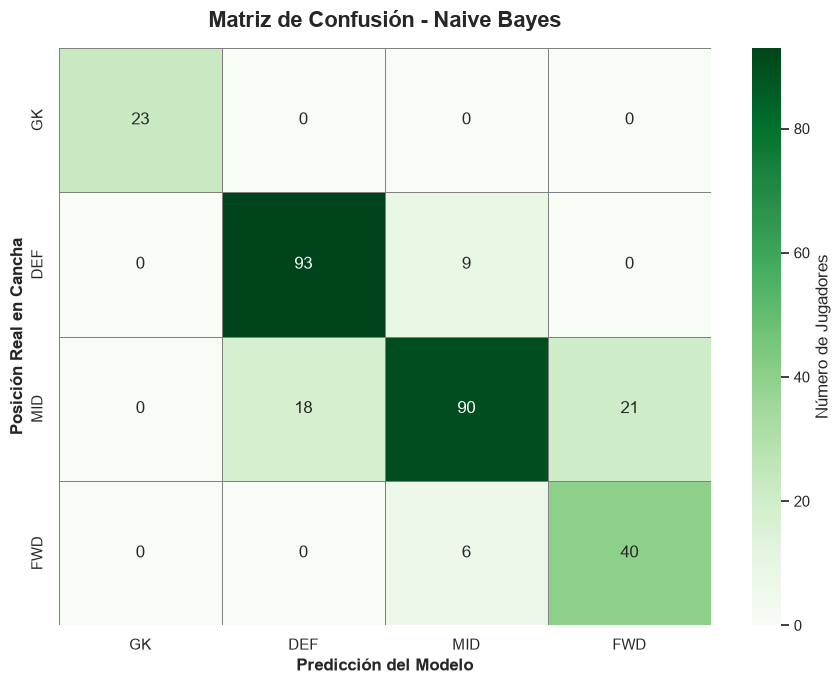


--- Ejecutando 5-Fold Cross-Validation para Naive Bayes ---
Accuracy de cada iteración: [0.8833 0.7833 0.7417 0.7875 0.7625]
 Accuracy Promedio Real (NB): 0.7917 (79.17%)
 Desviación estándar (Margen de error): ±0.0487
 Tiempo total de ejecución (5 iteraciones): 0.121421 segundos
 Consumo máximo de memoria RAM detectado: 0.982368 MB



In [328]:
# Matriz de Confusión y Cross-Validation (Naive Bayes)

# Visualización de la Matriz de Confusión
plt.figure(figsize=(9, 7))
orden_cancha = ['GK', 'DEF', 'MID', 'FWD'] 
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=orden_cancha)

# Usamos el color 'Greens' para diferenciar visualmente a Naive Bayes de KNN ('Blues')
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greens', 
            xticklabels=orden_cancha, yticklabels=orden_cancha,
            linewidths=0.5, linecolor='gray', cbar_kws={'label': 'Número de Jugadores'})

plt.title('Matriz de Confusión - Naive Bayes', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Predicción del Modelo', fontsize=12, fontweight='bold')
plt.ylabel('Posición Real en Cancha', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Validación Cruzada (5-Fold CV) para Naive Bayes
print("\n--- Ejecutando 5-Fold Cross-Validation para Naive Bayes ---")

# Iniciar medición
tracemalloc.start()
start_time_cv = time.time()

# cross_val_score entrena y evalúa 5 veces
puntuaciones_cv_nb = cross_val_score(nb_model, X_train_scaled, y_train, cv=5, scoring='accuracy')

# Capturar memoria y detener medición
current_mem_cv, peak_mem_cv = tracemalloc.get_traced_memory()
tracemalloc.stop()
end_time_cv = time.time()

# Cálculos de eficiencia
tiempo_ejecucion_cv_nb = end_time_cv - start_time_cv
ram_usada_mb_cv_nb = peak_mem_cv / (1024 * 1024) 

print(f"Accuracy de cada iteración: {np.round(puntuaciones_cv_nb, 4)}")
print(f" Accuracy Promedio Real (NB): {puntuaciones_cv_nb.mean():.4f} ({(puntuaciones_cv_nb.mean()*100):.2f}%)")
print(f" Desviación estándar (Margen de error): ±{puntuaciones_cv_nb.std():.4f}")
print(f" Tiempo total de ejecución (5 iteraciones): {tiempo_ejecucion_cv_nb:.6f} segundos")
print(f" Consumo máximo de memoria RAM detectado: {ram_usada_mb_cv_nb:.6f} MB\n")

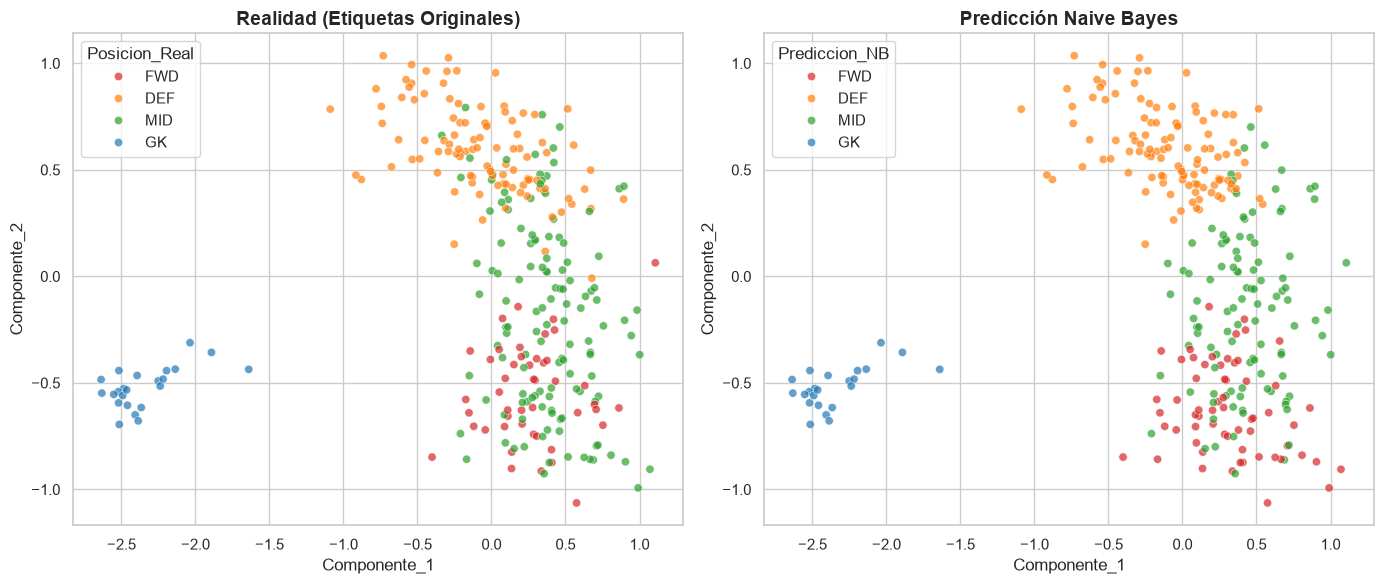

In [329]:
# Reduccion de 34 dimensiones a 2D para observar la confusión de Naive Bayes")

# Comprimo los datos de prueba a 2 dimensiones (PCA)
pca = PCA(n_components=2)
X_test_pca = pca.fit_transform(X_test_scaled)

# Creo un DataFrame para comparar
df_pca = pd.DataFrame({'Componente_1': X_test_pca[:, 0], 
                       'Componente_2': X_test_pca[:, 1], 
                       'Posicion_Real': y_test, 
                       'Prediccion_NB': y_pred_nb})

# Gráfica: Realidad vs Bayes
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
orden_colores = {'GK': '#1f77b4', 'DEF': '#ff7f0e', 'MID': '#2ca02c', 'FWD': '#d62728'}

# Gráfica A: Lo Real
sns.scatterplot(data=df_pca, x='Componente_1', y='Componente_2', hue='Posicion_Real', 
                palette=orden_colores, ax=axes[0], alpha=0.7)
axes[0].set_title('Realidad (Etiquetas Originales)', fontsize=14, fontweight='bold')

# Gráfica B: La "Alucinación" de Naive Bayes
sns.scatterplot(data=df_pca, x='Componente_1', y='Componente_2', hue='Prediccion_NB', 
                palette=orden_colores, ax=axes[1], alpha=0.7)
axes[1].set_title('Predicción Naive Bayes', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### Exploración no supervisada: K-Means

También probaré K-Means para observar si los atributos forman grupos sin utilizar las etiquetas de posición durante el entrenamiento.

In [330]:
tracemalloc.start()
start_time_km = time.time()
# Se entrena el modelo K means.
# n_init=10 corre el algoritmo con 10 inicios al azar y se queda con el mejor
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_model.fit(X_train_scaled) 

# Generamos predicciones (Agrupaciones 0, 1, 2, 3)
y_pred_km = kmeans_model.predict(X_test_scaled)

current_mem_km, peak_mem_km = tracemalloc.get_traced_memory()
tracemalloc.stop()
end_time_km = time.time()

# Cálculos de eficiencia
tiempo_ejecucion_km = end_time_km - start_time_km
ram_usada_mb_km = peak_mem_km / (1024 * 1024)

print(f"Tiempo total de ejecución (K-Means): {tiempo_ejecucion_km:.6f} segundos")
print(f"Consumo máximo de memoria RAM detectado: {ram_usada_mb_km:.6f} MB\n")

Tiempo total de ejecución (K-Means): 0.123950 segundos
Consumo máximo de memoria RAM detectado: 0.708158 MB



c:\Users\oscar\miniconda3\envs\sports-analytics\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


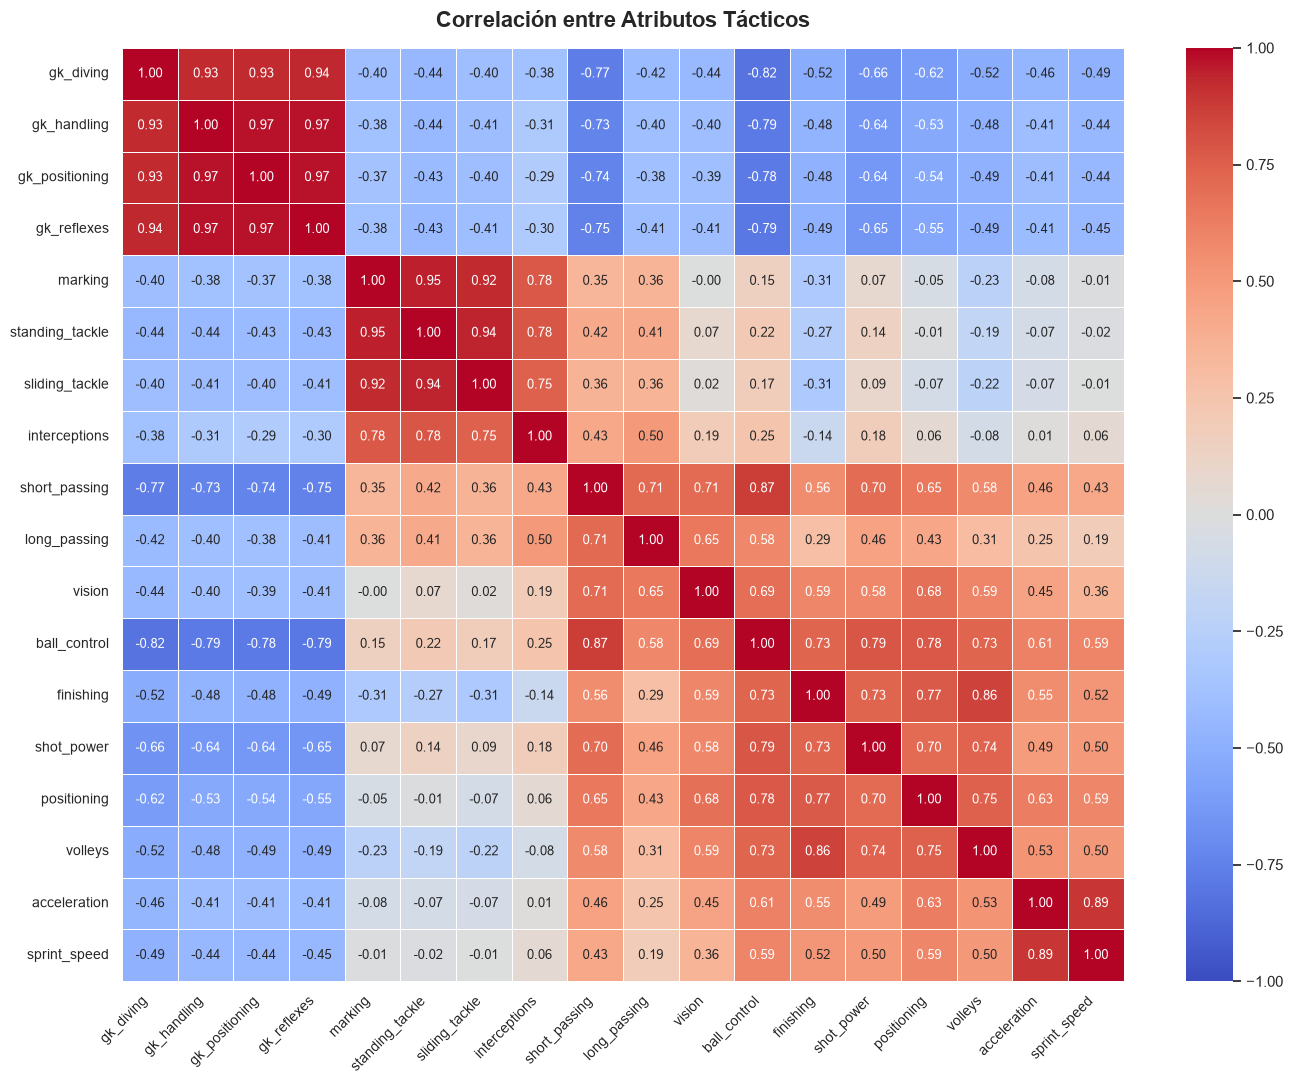

 Tiempo de ejecución: 0.102577 seg |  RAM usada: 0.849119 MB

Predicción por Predicción (Evaluación Individual de K-Means)


c:\Users\oscar\miniconda3\envs\sports-analytics\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


Clúster Asignado por IA,0,1,2,3
Posición Real,,,,
DEF,55,0,0,47
FWD,0,45,0,1
GK,0,0,23,0
MID,6,68,0,55


In [331]:


# Selección táctica de variables representativas
cols_clave = [
    # Portero (GK)
    'gk_diving', 'gk_handling', 'gk_positioning', 'gk_reflexes',
    # Defensa (DEF)
    'marking', 'standing_tackle', 'sliding_tackle', 'interceptions',
    # Medio (MID)
    'short_passing', 'long_passing', 'vision', 'ball_control',
    # Ataque (FWD)
    'finishing', 'shot_power', 'positioning', 'volleys',
    # Físico
    'acceleration', 'sprint_speed'
]

# Calculamos la matriz de correlación
corr_matrix = X[cols_clave].corr() 

plt.figure(figsize=(14, 11)) 
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, 
            linewidths=0.5, annot_kws={"size": 9})

plt.title(' Correlación entre Atributos Tácticos ', fontsize=16, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

# Entrenamiento de K means
# Iniciar medición
tracemalloc.start()
start_time_km = time.time()

# Entrenamos el modelo No Supervisado
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_model.fit(X_train_scaled) 

# Generamos predicciones (Agrupaciones 0, 1, 2, 3)
y_pred_km = kmeans_model.predict(X_test_scaled)

# Detener medición
current_mem_km, peak_mem_km = tracemalloc.get_traced_memory()
tracemalloc.stop()
end_time_km = time.time()

print(f" Tiempo de ejecución: {end_time_km - start_time_km:.6f} seg |  RAM usada: {peak_mem_km / (1024*1024):.6f} MB\n")


print("Predicción por Predicción (Evaluación Individual de K-Means)")
# Usamos una tabla cruzada para auditar qué número de clúster le asignó a cada posición real
matriz_kmeans = pd.crosstab(y_test, y_pred_km, rownames=['Posición Real'], colnames=['Clúster Asignado por IA'])
display(matriz_kmeans)


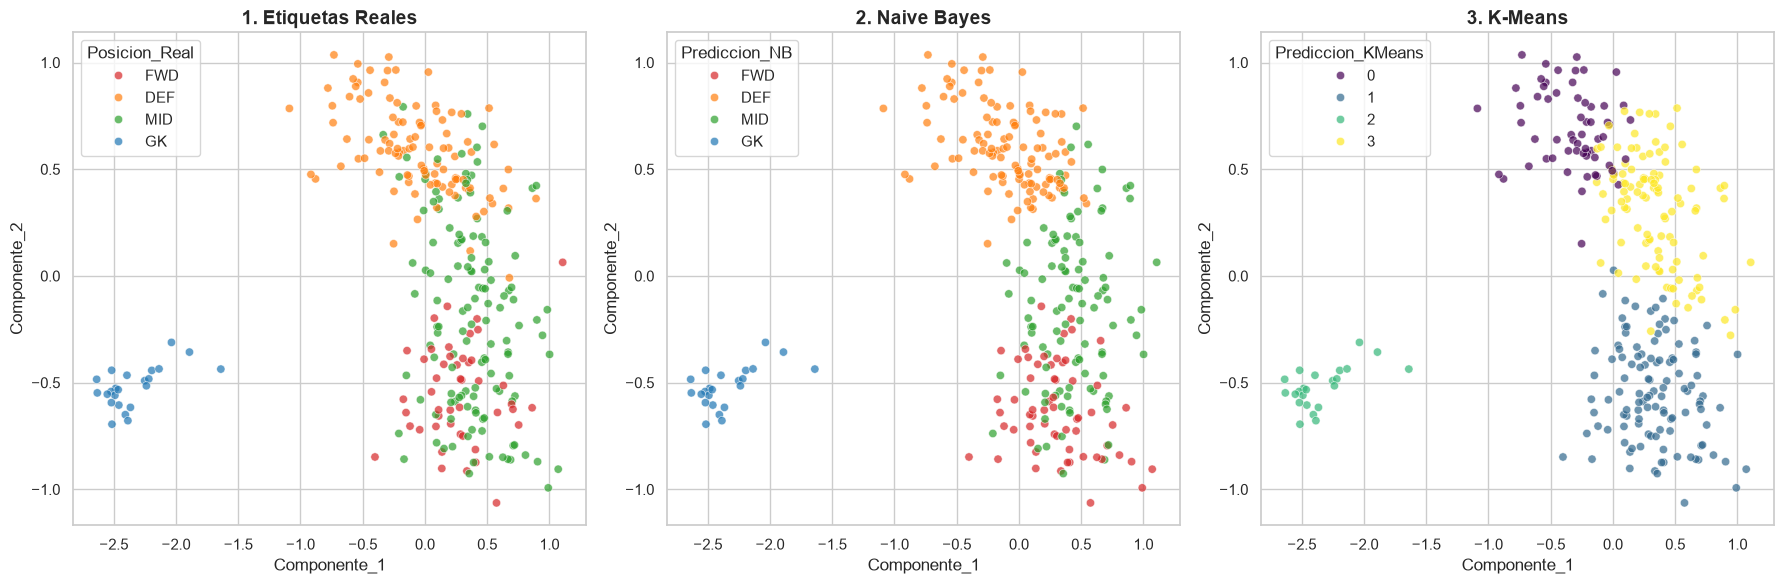

In [332]:
# Añado la prediccion
df_pca["Prediccion_KMeans"] = y_pred_km

# Gráfica Triple de Benchmark: Realidad vs Bayes vs K-Means
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
orden_colores = {"GK": "#1f77b4", "DEF": "#ff7f0e", "MID": "#2ca02c", "FWD": "#d62728"}
# Usamos una paleta distinta para K-Means porque no sabemos qué número asignó a cada posición
colores_kmeans = "viridis" 

# Gráfica A: Realidad
sns.scatterplot(data=df_pca, x="Componente_1", y="Componente_2", hue="Posicion_Real", 
                palette=orden_colores, ax=axes[0], alpha=0.7)
axes[0].set_title("1. Etiquetas Reales", fontsize=14, fontweight="bold")

# Gráfica B: Naive Bayes
sns.scatterplot(data=df_pca, x="Componente_1", y="Componente_2", hue="Prediccion_NB", 
                palette=orden_colores, ax=axes[1], alpha=0.7)
axes[1].set_title("2. Naive Bayes", fontsize=14, fontweight="bold")

# Gráfica C: K-Means
sns.scatterplot(data=df_pca, x="Componente_1", y="Componente_2", hue="Prediccion_KMeans", 
                palette=colores_kmeans, ax=axes[2], alpha=0.7, legend="full")
axes[2].set_title("3. K-Means", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

In [333]:
# Evaluación de K-Means y Gráfica Triple Comparativa


# Silhouette Score: Evalúa la separación y compacidad de los clusters (-1 a 1)
sil_score = silhouette_score(X_test_scaled, y_pred_km)

# Adjusted Rand Index (ARI): Compara la similitud entre los clusters a ciegas y las posiciones reales (0 a 1)
ari_score = adjusted_rand_score(y_test, y_pred_km)

print(f" Silhouette Score (Calidad Matemática de los Clústers): {sil_score:.4f}")
print(f" Adjusted Rand Index (Similitud con la Realidad): {ari_score:.4f} ({(ari_score*100):.2f}%)\n")


 Silhouette Score (Calidad Matemática de los Clústers): 0.2202
 Adjusted Rand Index (Similitud con la Realidad): 0.3205 (32.05%)



### Comparación de clasificadores

Compararé KNN y Naive Bayes con validación cruzada de 10 particiones, métricas por posición y recursos utilizados.

In [334]:


# Uso de ambos modelos
knn_model = KNeighborsClassifier(n_neighbors=best_k) 
nb_model = GaussianNB()

# Auditoría a KNN
tracemalloc.start()
start_time_knn = time.time()
cv_knn = cross_val_score(knn_model, X_train_scaled, y_train, cv=10, scoring='accuracy')
current_mem, peak_mem_knn = tracemalloc.get_traced_memory()
tracemalloc.stop()
time_knn = time.time() - start_time_knn
ram_knn = peak_mem_knn / (1024 * 1024)

# Naive Bayes 
tracemalloc.start()
start_time_nb = time.time()
cv_nb = cross_val_score(nb_model, X_train_scaled, y_train, cv=10, scoring='accuracy')
current_mem, peak_mem_nb = tracemalloc.get_traced_memory()
tracemalloc.stop()
time_nb = time.time() - start_time_nb
ram_nb = peak_mem_nb / (1024 * 1024)

# Tomo F1 Score por cada posicion
f1_knn_pos = f1_score(y_test, y_pred_final, labels=['GK', 'DEF', 'MID', 'FWD'], average=None)
f1_nb_pos = f1_score(y_test, y_pred_nb, labels=['GK', 'DEF', 'MID', 'FWD'], average=None)

# Consturyo la tabla de comparaciones
df_benchmark = pd.DataFrame({
    'Modelo Evaluado': ['K-Nearest Neighbors (K óptimo)', 'Gaussian Naive Bayes'],
    'Eficacia General (10-Fold)': [f"{cv_knn.mean()*100:.2f}%", f"{cv_nb.mean()*100:.2f}%"],
    'Estabilidad (± Desv)': [f"± {cv_knn.std():.4f}", f"± {cv_nb.std():.4f}"],
    'Eficacia Porteros (GK)': [f"{f1_knn_pos[0]*100:.1f}%", f"{f1_nb_pos[0]*100:.1f}%"],
    'Eficacia Defensas (DEF)': [f"{f1_knn_pos[1]*100:.1f}%", f"{f1_nb_pos[1]*100:.1f}%"],
    'Eficacia Medios (MID)': [f"{f1_knn_pos[2]*100:.1f}%", f"{f1_nb_pos[2]*100:.1f}%"],
    'Eficacia Delanteros (FWD)': [f"{f1_knn_pos[3]*100:.1f}%", f"{f1_nb_pos[3]*100:.1f}%"],
    'Tiempo Total (segundos)': [f"{time_knn:.4f}", f"{time_nb:.4f}"],
    'Pico RAM (MB)': [f"{ram_knn:.4f}", f"{ram_nb:.4f}"]
})

print("\n Veredicto de Rendimiento, Eficiencia y Precisión Táctica:")
display(df_benchmark)


 Veredicto de Rendimiento, Eficiencia y Precisión Táctica:


,Modelo Evaluado,Eficacia General (10-Fold),Estabilidad (± Desv),Eficacia Porteros (GK),Eficacia Defensas (DEF),Eficacia Medios (MID),Eficacia Delanteros (FWD),Tiempo Total (segundos),Pico RAM (MB)
0,K-Nearest Neighbors (K óptimo),87.58%,± 0.0336,100.0%,94.2%,89.5%,83.1%,0.2528,0.7354
1,Gaussian Naive Bayes,79.08%,± 0.0518,100.0%,87.3%,76.9%,74.8%,0.1695,0.8842


### De clasificación a regresión

Además de estimar la posición, probaré si los atributos del jugador permiten estimar su `overall_rating`. Compararé KNN y Random Forest con las mismas particiones de entrenamiento y prueba.

In [335]:
# Defino el nuevo target
target_reg = 'overall_rating'
y_reg = df_knn[target_reg] # X sigue siendo el mismo df de las caracteristicas

# Voy a volver a dividir y mezclar para la clasificacion no se mezcle o genere un overfitting
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y_reg, test_size=0.2, random_state=42)

X_train_r_scaled = scaler.fit_transform(X_train_r)
X_test_r_scaled = scaler.transform(X_test_r)

# Entreno el modelo de Regresión
# Iniciar de tiempo
tracemalloc.start()
start_time_reg = time.time()

# Uso KNeighborsRegressor con K neighbors igual a 5
knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(X_train_r_scaled, y_train_r)

# Generar las Predicciones Numéricas
y_pred_r = knn_reg.predict(X_test_r_scaled)

# Fin de tiempo
current_mem_reg, peak_mem_reg = tracemalloc.get_traced_memory()
tracemalloc.stop()
time_reg = time.time() - start_time_reg
ram_reg = peak_mem_reg / (1024 * 1024)

# Ahora evaluo las regresiones
mae = mean_absolute_error(y_test_r, y_pred_r)
rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))
r2 = r2_score(y_test_r, y_pred_r)

print(f"Tiempo total de ejecución: {time_reg:.6f} segundos")
print(f"Consumo de RAM detectado: {ram_reg:.6f} MB\n")

print("Métricas de Error del Modelo:")
print(f"MAE (Margen de error promedio): ± {mae:.2f} puntos de rating")
print(f"RMSE (Error cuadrático medio): ± {rmse:.2f} puntos")
print(f"R² Score (Precisión de ajuste): {r2:.4f} ({(r2*100):.2f}%)")

# Muestro la prediccion comparado a como es realmente
df_resultados_reg = pd.DataFrame({
    'Calidad Real': y_test_r.values[:10],
    'Predicción KNN': np.round(y_pred_r[:10], 1),
    'Diferencia': np.round(abs(y_test_r.values[:10] - y_pred_r[:10]), 1)
})
print("\n Muestra de 10 Jugadores (Realidad vs Prediccion):")
display(df_resultados_reg)

Tiempo total de ejecución: 0.091710 segundos
Consumo de RAM detectado: 0.447887 MB

Métricas de Error del Modelo:
MAE (Margen de error promedio): ± 1.72 puntos de rating
RMSE (Error cuadrático medio): ± 2.22 puntos
R² Score (Precisión de ajuste): 0.8196 (81.96%)

 Muestra de 10 Jugadores (Realidad vs Prediccion):


,Calidad Real,Predicción KNN,Diferencia
0,72.0,71.2,0.8
1,69.0,72.0,3.0
2,78.0,74.8,3.2
3,78.0,80.6,2.6
4,78.0,75.8,2.2
5,74.0,76.0,2.0
6,73.0,73.0,0.0
7,75.0,74.0,1.0
8,70.0,71.0,1.0
9,80.0,74.8,5.2


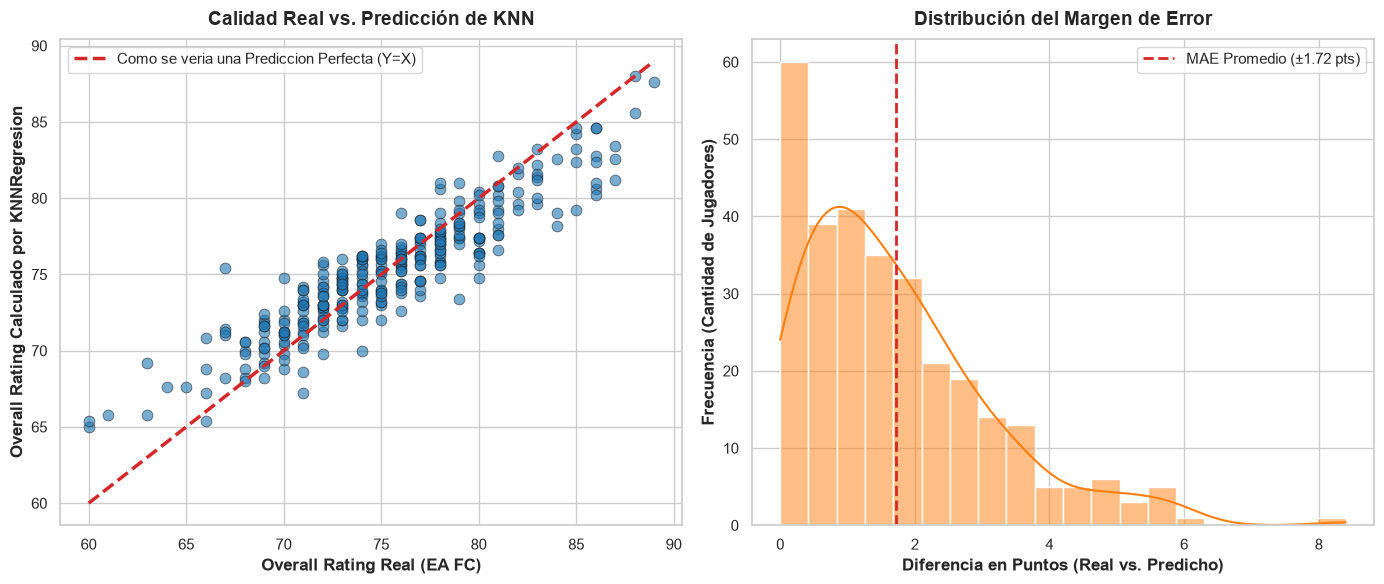

In [336]:
# Creo un DF para la visualizacion
df_reg_viz = pd.DataFrame({
    'Realidad': y_test_r,
    'Predicción_KNN': y_pred_r
})

# Calculo el error absoluto por cada jugador
df_reg_viz['Error_Absoluto'] = abs(df_reg_viz['Realidad'] - df_reg_viz['Predicción_KNN'])


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.set_theme(style="whitegrid")


# Gráfico 1: Dispersión de Medias reales en contra de las predicciones
sns.scatterplot(data=df_reg_viz, x='Realidad', y='Predicción_KNN', 
                alpha=0.6, color='#1f77b4', edgecolor='k', s=60, ax=axes[0])
rango_min = min(df_reg_viz['Realidad'].min(), df_reg_viz['Predicción_KNN'].min())
rango_max = max(df_reg_viz['Realidad'].max(), df_reg_viz['Predicción_KNN'].max())
axes[0].plot([rango_min, rango_max], [rango_min, rango_max], 
             color='#d62728', linestyle='--', linewidth=2.5, label='Como se veria una Prediccion Perfecta (Y=X)')

axes[0].set_title('Calidad Real vs. Predicción de KNN', fontsize=14, fontweight='bold', pad=10)
axes[0].set_xlabel('Overall Rating Real (EA FC)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Overall Rating Calculado por KNNRegresion', fontsize=12, fontweight='bold')
axes[0].legend()


# Gráfico 2: Distribución de los Errores
sns.histplot(data=df_reg_viz, x='Error_Absoluto', kde=True, 
             color='#ff7f0e', bins=20, ax=axes[1])

# Dibujo una linea en la que se marca el MAE
mae_obtenido = df_reg_viz['Error_Absoluto'].mean()
axes[1].axvline(mae_obtenido, color='#d62728', linestyle='dashed', linewidth=2, 
                label=f'MAE Promedio (±{mae_obtenido:.2f} pts)')

axes[1].set_title('Distribución del Margen de Error', fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel('Diferencia en Puntos (Real vs. Predicho)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Frecuencia (Cantidad de Jugadores)', fontsize=12, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

In [337]:
# Vamos a usar random forest, especificamente random forrest regresor para tener otra comparacion

In [338]:
# Inicio de prueba de tiempo
tracemalloc.start()
start_time_rf = time.time()

# Entrenamiento de random forest con 100 arboles
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_r_scaled, y_train_r)

# Genero las predicciones numericas
y_pred_rf = rf_model.predict(X_test_r_scaled)

# Detengo la prueba de tiempo
current_mem, peak_mem_rf = tracemalloc.get_traced_memory()
tracemalloc.stop()
time_rf = time.time() - start_time_rf
ram_rf = peak_mem_rf / (1024 * 1024)

# Evaluaciones
mae_rf = mean_absolute_error(y_test_r, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test_r, y_pred_rf))
r2_rf = r2_score(y_test_r, y_pred_rf)

print(f" Tiempo total de ejecución (Random Forest): {time_rf:.4f} seg")
print(f" Consumo máximo de RAM detectado: {ram_rf:.4f} MB\n")

print(" Métricas de Error (Random Forest):")
print(f" MAE (Margen de error promedio): ± {mae_rf:.2f} puntos")
print(f" RMSE (Error cuadrático medio): ± {rmse_rf:.2f} puntos")
print(f" R² Score (Precisión de ajuste): {r2_rf:.4f} ({(r2_rf*100):.2f}%)\n")


print(f" Comparacion de MAE: KNN (±{mae:.2f}) vs Random Forest (±{mae_rf:.2f})")

 Tiempo total de ejecución (Random Forest): 1.1793 seg
 Consumo máximo de RAM detectado: 0.4885 MB

 Métricas de Error (Random Forest):
 MAE (Margen de error promedio): ± 0.01 puntos
 RMSE (Error cuadrático medio): ± 0.09 puntos
 R² Score (Precisión de ajuste): 0.9997 (99.97%)

 Comparacion de MAE: KNN (±1.72) vs Random Forest (±0.01)


### Experimento inicial: fuga del objetivo

> En esta primera prueba incluí `overall_rating` entre las variables de entrada aunque también era el objetivo. Esto provoca **fuga de información**, por lo que las métricas de ese experimento no representan el rendimiento real del modelo. La comparación válida se realiza más adelante, excluyendo esa columna de los predictores.

C:\Users\oscar\AppData\Local\Temp\ipykernel_31688\2932107614.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importancia, x='Peso_Porcentual', y='Atributo', palette='rocket')


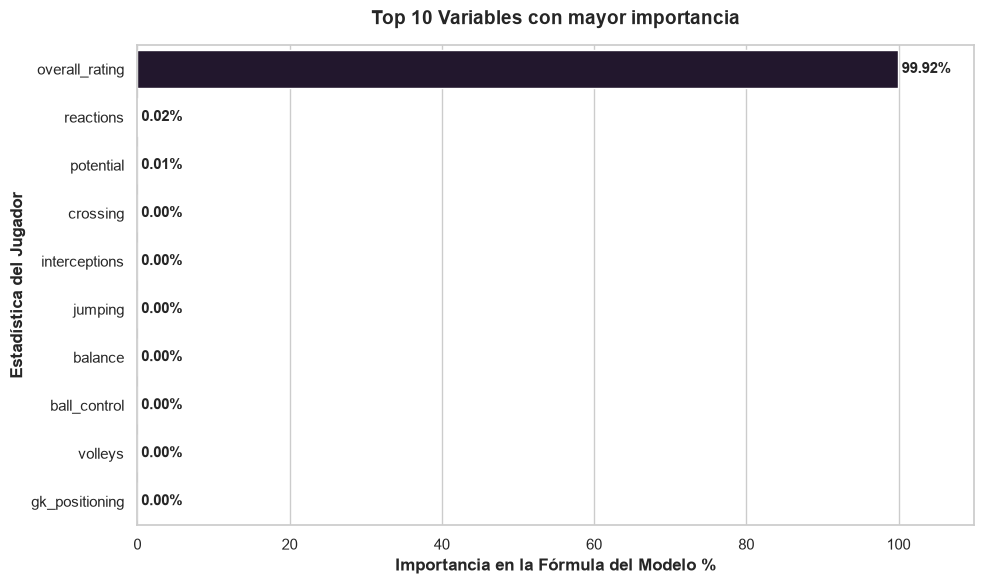

In [339]:


# Voy a extraer la importancia de cada cualidad con feature_importances_
importancias = rf_model.feature_importances_

# Creo un DataFrame combinando los nombres de las columnas y su peso matemático
df_importancia = pd.DataFrame({
    'Atributo': X.columns,
    'Peso_Porcentual': importancias * 100 # Multiplicamos por 100 para leerlo en porcentaje
})

# Ordeno de mayor a menor y tomar el Top 10, asi no saturo la grafica
df_importancia = df_importancia.sort_values(by='Peso_Porcentual', ascending=False).head(10)

# Genero una grafica de barras
plt.figure(figsize=(10, 6))
sns.barplot(data=df_importancia, x='Peso_Porcentual', y='Atributo', palette='rocket')

plt.title('Top 10 Variables con mayor importancia', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Importancia en la Fórmula del Modelo %', fontsize=12, fontweight='bold')
plt.ylabel('Estadística del Jugador', fontsize=12, fontweight='bold')
for index, value in enumerate(df_importancia['Peso_Porcentual']):
    plt.text(value + 0.5, index, f'{value:.2f}%', va='center', fontsize=11, fontweight='bold')

plt.xlim(0, max(df_importancia['Peso_Porcentual']) + 10)
plt.tight_layout()
plt.show()

*Aqui cometo el error de haber entrenado sin quitar overall rating, esto genero un overfitting en random forest, para motivos de documentacion voy a dejar ambos*

In [340]:
# Defino ahora si de forma correcta los targets como la y
target_reg = "overall_rating"
y_reg = df_knn[target_reg]

# Me aseguro que X_reg no contenga rating ni columnas que no uso
columnas_excluir_reg = ["id", "player_fifa_api_id", "player_api_id", "date", "preferred_foot", "position", "overall_rating"]
features_reg = [col for col in df_knn.columns if col not in columnas_excluir_reg]
X_reg = df_knn[features_reg]

#  División y Escalado nuevamente
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Uso StandardScaler
scaler_reg = StandardScaler()
X_train_r_scaled = scaler_reg.fit_transform(X_train_r)
X_test_r_scaled = scaler_reg.transform(X_test_r)

# Machine learnig de KNNregresor
tracemalloc.start()
start_time_knn = time.time()
knn_reg = KNeighborsRegressor(n_neighbors=5) # Elegi 5 al ser el mas optimo
knn_reg.fit(X_train_r_scaled, y_train_r)
y_pred_knn_r = knn_reg.predict(X_test_r_scaled)
current_mem, peak_mem_knn = tracemalloc.get_traced_memory()
tracemalloc.stop()
time_knn = time.time() - start_time_knn
ram_knn = peak_mem_knn / (1024 * 1024)

mae_knn = mean_absolute_error(y_test_r, y_pred_knn_r)
r2_knn = r2_score(y_test_r, y_pred_knn_r)

# Machine learning de Random Forest Regressor

tracemalloc.start()
start_time_rf = time.time()
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train_r_scaled, y_train_r)
y_pred_rf_r = rf_reg.predict(X_test_r_scaled)
current_mem, peak_mem_rf = tracemalloc.get_traced_memory()
tracemalloc.stop()
time_rf = time.time() - start_time_rf
ram_rf = peak_mem_rf / (1024 * 1024)

mae_rf = mean_absolute_error(y_test_r, y_pred_rf_r)
r2_rf = r2_score(y_test_r, y_pred_rf_r)

# Creo la tabla comparativa
df_benchmark_reg = pd.DataFrame({
    "Modelo de Regresión": ["K-Nearest Neighbors (K=10)", "Random Forest (100 Árboles)"],
    "R² Score (Ajuste)": [f"{r2_knn*100:.2f}%", f"{r2_rf*100:.2f}%"],
    "MAE (Margen de Error)": [f"± {mae_knn:.2f} pts", f"± {mae_rf:.2f} pts"],
    "Tiempo Total (seg)": [f"{time_knn:.4f}", f"{time_rf:.4f}"],
    "Pico de RAM (MB)": [f"{ram_knn:.4f}", f"{ram_rf:.4f}"]
})

print("\nPredicción de Calidad General (Overall Rating):")
display(df_benchmark_reg)




Predicción de Calidad General (Overall Rating):


,Modelo de Regresión,R² Score (Ajuste),MAE (Margen de Error),Tiempo Total (seg),Pico de RAM (MB)
0,K-Nearest Neighbors (K=10),78.08%,± 1.89 pts,0.0199,0.4336
1,Random Forest (100 Árboles),83.93%,± 1.53 pts,1.6289,0.3376


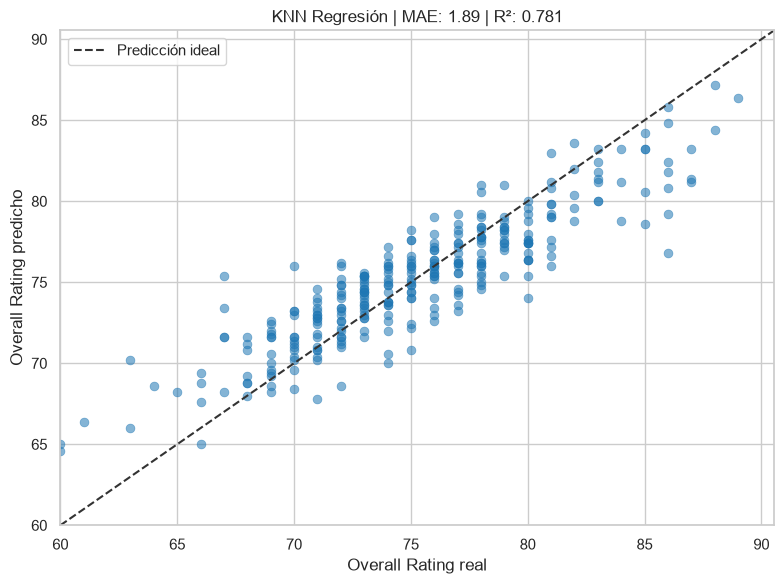

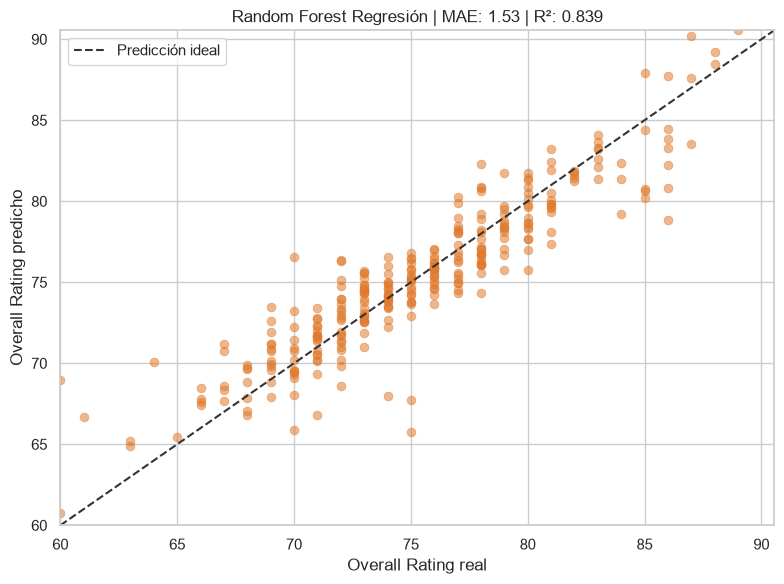

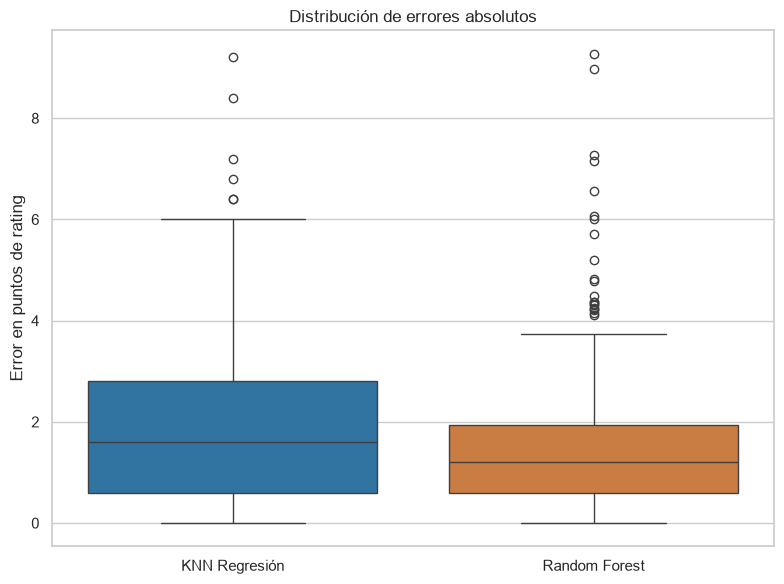

In [341]:
# Comparación visual de las predicciones sobre el mismo conjunto de prueba

df_comparacion_reg = pd.DataFrame({
    "Realidad": np.asarray(y_test_r),
    "Predicción KNN": y_pred_knn_r,
    "Predicción Random Forest": y_pred_rf_r
})

# Los dos gráficos de dispersión comparten límites para facilitar la comparación
limite_min = min(df_comparacion_reg["Realidad"].min(), df_comparacion_reg["Predicción KNN"].min(), df_comparacion_reg["Predicción Random Forest"].min())
limite_max = max(df_comparacion_reg["Realidad"].max(), df_comparacion_reg["Predicción KNN"].max(), df_comparacion_reg["Predicción Random Forest"].max())
sns.set_theme(style="whitegrid")

# Predicciones de KNN
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_comparacion_reg, x="Realidad", y="Predicción KNN",
    alpha=0.55, color="#1f77b4", edgecolor=None, s=40
 )
plt.plot([limite_min, limite_max], [limite_min, limite_max],
         color="#333333", linestyle="--", linewidth=1.5, label="Predicción ideal")
plt.xlim(limite_min, limite_max)
plt.ylim(limite_min, limite_max)
plt.title(f"KNN Regresión | MAE: {mae_knn:.2f} | R²: {r2_knn:.3f}")
plt.xlabel("Overall Rating real")
plt.ylabel("Overall Rating predicho")
plt.legend()
plt.tight_layout()
plt.show()

# Predicciones de Random Forest
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_comparacion_reg, x="Realidad", y="Predicción Random Forest",
    alpha=0.55, color="#e07a2d", edgecolor=None, s=40
 )
plt.plot([limite_min, limite_max], [limite_min, limite_max],
         color="#333333", linestyle="--", linewidth=1.5, label="Predicción ideal")
plt.xlim(limite_min, limite_max)
plt.ylim(limite_min, limite_max)
plt.title(f"Random Forest Regresión | MAE: {mae_rf:.2f} | R²: {r2_rf:.3f}")
plt.xlabel("Overall Rating real")
plt.ylabel("Overall Rating predicho")
plt.legend()
plt.tight_layout()
plt.show()

# Comparación de errores absolutos para cada jugador
df_errores_reg = pd.DataFrame({
    "KNN Regresión": abs(df_comparacion_reg["Realidad"] - df_comparacion_reg["Predicción KNN"]),
    "Random Forest": abs(df_comparacion_reg["Realidad"] - df_comparacion_reg["Predicción Random Forest"])
}).melt(var_name="Modelo", value_name="Error absoluto")

plt.figure(figsize=(8, 6))
sns.boxplot(data=df_errores_reg, x="Modelo", y="Error absoluto", hue="Modelo",
            palette=["#1f77b4", "#e07a2d"], legend=False)
plt.title("Distribución de errores absolutos")
plt.xlabel("")
plt.ylabel("Error en puntos de rating")
plt.tight_layout()
plt.show()

C:\Users\oscar\AppData\Local\Temp\ipykernel_31688\3549011280.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importancia_real, x="Peso_Porcentual", y="Atributo", palette="crest")


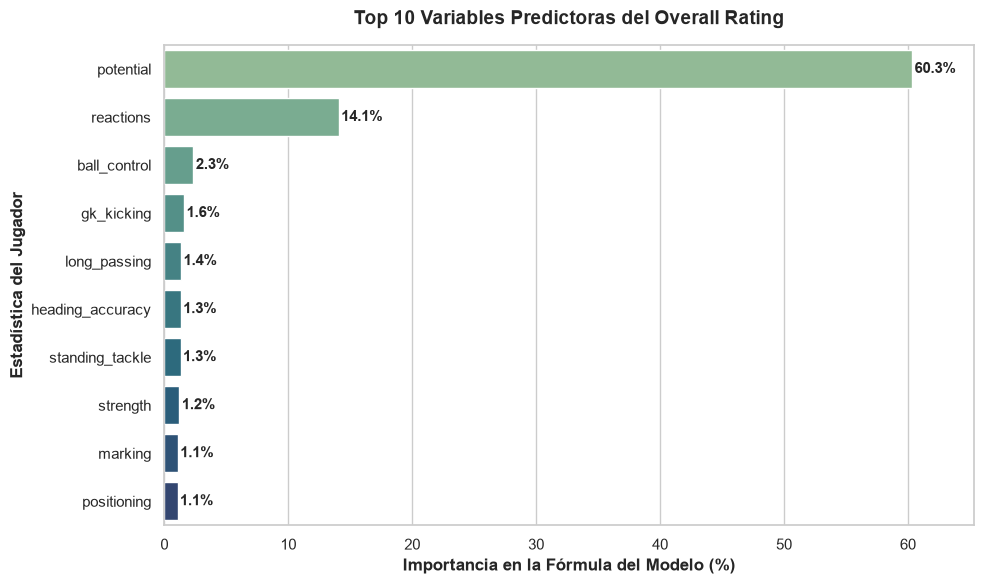

In [342]:
# Observo la Feature Importance a Random Forest 
importancias_reales = rf_reg.feature_importances_
df_importancia_real = pd.DataFrame({"Atributo": features_reg, "Peso_Porcentual": importancias_reales * 100})
df_importancia_real = df_importancia_real.sort_values(by="Peso_Porcentual", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_importancia_real, x="Peso_Porcentual", y="Atributo", palette="crest")
plt.title("Top 10 Variables Predictoras del Overall Rating", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Importancia en la Fórmula del Modelo (%)", fontsize=12, fontweight="bold")
plt.ylabel("Estadística del Jugador", fontsize=12, fontweight="bold")
for index, value in enumerate(df_importancia_real["Peso_Porcentual"]):
    plt.text(value + 0.2, index, f"{value:.1f}%", va="center", fontsize=11, fontweight="bold")
plt.xlim(0, max(df_importancia_real["Peso_Porcentual"]) + 5)
plt.tight_layout()
plt.show()

### Aplicación al scouting

Con las predicciones de posición y rating, crearé una clasificación sencilla por rangos de calidad para revisar cómo podría apoyar un reporte de scouting.

In [344]:
# Definimo los rangos de calidady sus etiquetas
rangos = [0, 64, 74, 84, 100]
etiquetas = ["Jugador Mediocre", "Jugador Promedio", "Jugador de Calidad", "Superestrella"]

# Creamos un DataFrame para comparar posición y calidad real/predicha
df_predictor = pd.DataFrame({
    "Posición_Real": y_test,
    "Posición_Predicha_KNN": y_pred_final,
    "Rating_Real": np.asarray(y_test_r),
    "Rating_Predicho_RF": np.round(y_pred_rf_r, 1)
})

# Aplicamos la categorización al rating predicho por Random Forest
df_predictor["Rango_Predictor"] = pd.cut(
    df_predictor["Rating_Predicho_RF"],
    bins=rangos,
    labels=etiquetas
)

# Aplicamos los mismos rangos a los ratings reales
df_predictor["Rango_Scouting_Real"] = pd.cut(
    df_predictor["Rating_Real"],
    bins=rangos,
    labels=etiquetas
)

# Mostramos jugadores predichos como jugador de calidad o superestrella
df_estrellas_ml = df_predictor[
    (df_predictor["Rango_Predictor"] == "Superestrella") |
    (df_predictor["Rango_Predictor"] == "Jugador de Calidad")
] .head(10)

print("\n Muestra del Reporte de Scouting (Jugadores Top detectados por IA):")
display(df_estrellas_ml)

# Cuántos jugadores catalogó el modelo en cada rango
print("\n Distribución de la Liga según el ML:")
display(df_predictor["Rango_Predictor"].value_counts())


 Muestra del Reporte de Scouting (Jugadores Top detectados por IA):


,Posición_Real,Posición_Predicha_KNN,Rating_Real,Rating_Predicho_RF,Rango_Predictor,Rango_Scouting_Real
524,MID,MID,78.0,76.0,Jugador de Calidad,Jugador de Calidad
1250,MID,MID,78.0,80.6,Jugador de Calidad,Jugador de Calidad
1439,MID,DEF,78.0,75.6,Jugador de Calidad,Jugador de Calidad
559,MID,MID,74.0,76.6,Jugador de Calidad,Jugador Promedio
694,DEF,DEF,75.0,74.6,Jugador de Calidad,Jugador de Calidad
1193,MID,DEF,80.0,75.8,Jugador de Calidad,Jugador de Calidad
997,FWD,FWD,74.0,74.6,Jugador de Calidad,Jugador Promedio
646,DEF,DEF,85.0,84.4,Superestrella,Superestrella
1117,DEF,DEF,76.0,75.8,Jugador de Calidad,Jugador de Calidad
783,DEF,DEF,78.0,76.2,Jugador de Calidad,Jugador de Calidad



 Distribución de la Liga según el ML:


Rango_Predictor
Jugador de Calidad    176
Jugador Promedio      113
Superestrella          10
Jugador Mediocre        1
Name: count, dtype: int64

In [346]:
# Evaluación final de las predicciones según el tipo de modelo

# KNN de clasificación: evalúa las posiciones predichas
print("Rendimiento de KNN para clasificación de posiciones:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_final):.3f}")
print(classification_report(y_test, y_pred_final, labels=["GK", "DEF", "MID", "FWD"], zero_division=0))

# Los modelos de regresión se evalúan con error y ajuste, no con accuracy de clasificación
rating_real = np.asarray(y_test_r)
predicciones_regresion = {
    "KNN Regresión": np.asarray(y_pred_knn_r),
    "Random Forest Regresión": np.asarray(y_pred_rf_r)
}

resultados_regresion = []
for nombre_modelo, prediccion in predicciones_regresion.items():
    resultados_regresion.append({
        "Modelo": nombre_modelo,
        "MAE (menor es mejor)": mean_absolute_error(rating_real, prediccion),
        "RMSE (menor es mejor)": np.sqrt(mean_squared_error(rating_real, prediccion)),
        "R² (mayor es mejor)": r2_score(rating_real, prediccion),
        "Predicciones a ±1 punto (%)": np.mean(np.abs(rating_real - prediccion) <= 1) * 100
    })

df_evaluacion_regresion = pd.DataFrame(resultados_regresion)
print("Evaluación numérica de los modelos de regresión del rating:")
display(df_evaluacion_regresion.round(3))

# Evaluación de calidad: ¿el jugador quedó en el rango correcto?
rangos_calidad = [0, 64, 74, 84, 100]
etiquetas_calidad = ["Jugador Mediocre", "Jugador Promedio", "Jugador de Calidad", "Superestrella"]
calidad_real = pd.cut(
    rating_real, bins=rangos_calidad, labels=etiquetas_calidad, include_lowest=True
 )

resultados_calidad = []
for nombre_modelo, prediccion in predicciones_regresion.items():
    calidad_predicha = pd.cut(
        np.clip(prediccion, rangos_calidad[0], rangos_calidad[-1]),
        bins=rangos_calidad, labels=etiquetas_calidad, include_lowest=True
    )
    reporte_calidad = classification_report(
        calidad_real, calidad_predicha, labels=etiquetas_calidad,
        output_dict=True, zero_division=0
    )
    resultados_calidad.append({
        "Modelo": nombre_modelo,
        "Acierto de rango (%)": accuracy_score(calidad_real, calidad_predicha) * 100,
        "Precision macro (%)": reporte_calidad["macro avg"]["precision"] * 100,
        "Recall macro (%)": reporte_calidad["macro avg"]["recall"] * 100,
        "F1 macro (%)": reporte_calidad["macro avg"]["f1-score"] * 100
    })
    print(f"\nCalidad predicha por {nombre_modelo} (por rango):")
    print(classification_report(
        calidad_real, calidad_predicha, labels=etiquetas_calidad, zero_division=0
    ))

df_evaluacion_calidad = pd.DataFrame(resultados_calidad)
print("Resumen: porcentaje de jugadores asignados al rango de calidad correcto:")
display(df_evaluacion_calidad.round(2))

Rendimiento de KNN para clasificación de posiciones:
Accuracy: 0.910
              precision    recall  f1-score   support

          GK       1.00      1.00      1.00        23
         DEF       0.92      0.96      0.94       102
         MID       0.90      0.89      0.89       129
         FWD       0.86      0.80      0.83        46

    accuracy                           0.91       300
   macro avg       0.92      0.91      0.92       300
weighted avg       0.91      0.91      0.91       300

Evaluación numérica de los modelos de regresión del rating:


,Modelo,MAE (menor es mejor),RMSE (menor es mejor),R² (mayor es mejor),Predicciones a ±1 punto (%)
0,KNN Regresión,1.887,2.448,0.781,38.667
1,Random Forest Regresión,1.531,2.096,0.839,44.667



Calidad predicha por KNN Regresión (por rango):
                    precision    recall  f1-score   support

  Jugador Mediocre       0.00      0.00      0.00         6
  Jugador Promedio       0.84      0.73      0.78       132
Jugador de Calidad       0.73      0.92      0.81       144
     Superestrella       1.00      0.33      0.50        18

          accuracy                           0.78       300
         macro avg       0.64      0.49      0.52       300
      weighted avg       0.78      0.78      0.76       300


Calidad predicha por Random Forest Regresión (por rango):
                    precision    recall  f1-score   support

  Jugador Mediocre       1.00      0.17      0.29         6
  Jugador Promedio       0.89      0.77      0.82       132
Jugador de Calidad       0.77      0.94      0.85       144
     Superestrella       0.90      0.50      0.64        18

          accuracy                           0.82       300
         macro avg       0.89      0.59      0.

,Modelo,Acierto de rango (%),Precision macro (%),Recall macro (%),F1 macro (%)
0,KNN Regresión,78.00,64.39,49.43,52.38
1,Random Forest Regresión,82.33,89.16,59.41,65.08


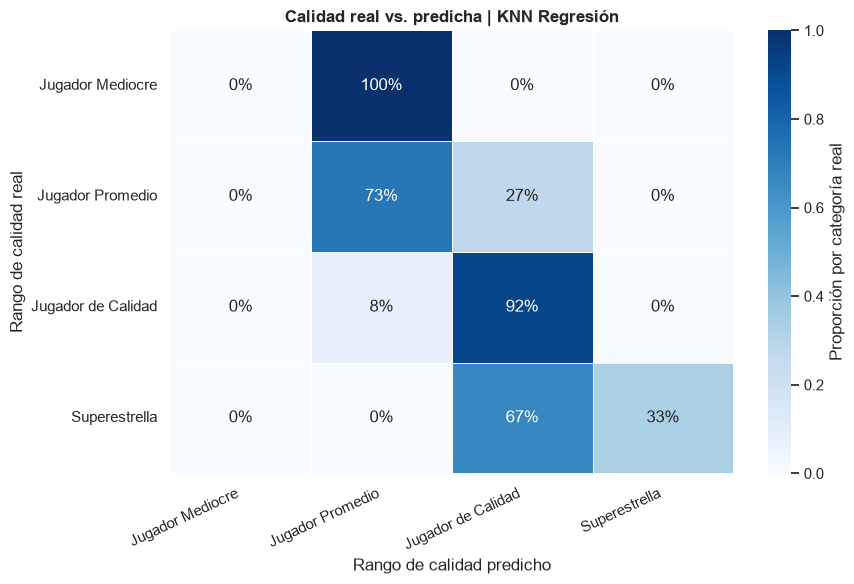

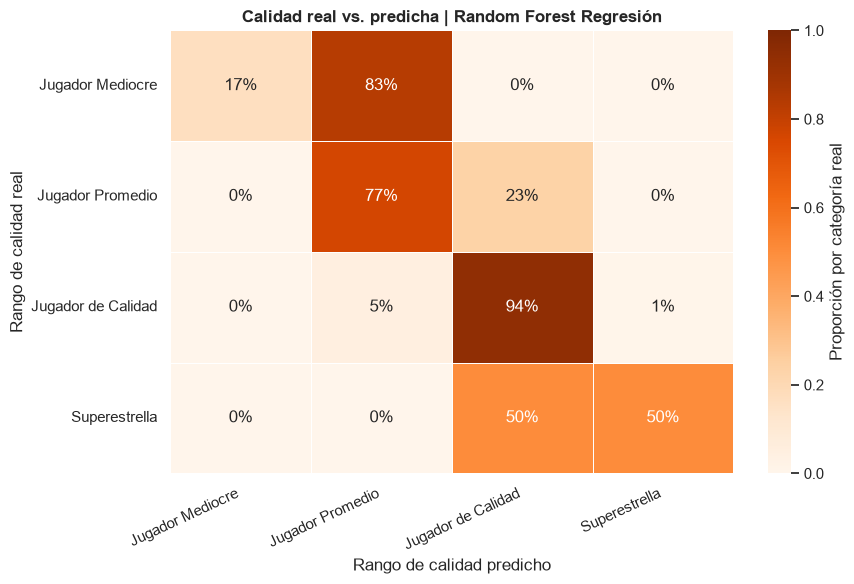

In [347]:
# Matrices de confusión para visualizar los rangos de calidad predichos
for nombre_modelo, prediccion, mapa_colores in [
    ("KNN Regresión", np.asarray(y_pred_knn_r), "Blues"),
    ("Random Forest Regresión", np.asarray(y_pred_rf_r), "Oranges")
    ]:
    calidad_predicha = pd.cut(
        np.clip(prediccion, rangos_calidad[0], rangos_calidad[-1]),
        bins=rangos_calidad, labels=etiquetas_calidad, include_lowest=True
    )
    matriz_calidad = confusion_matrix(
        calidad_real, calidad_predicha, labels=etiquetas_calidad, normalize="true"
    )

    plt.figure(figsize=(9, 6))
    sns.heatmap(
        matriz_calidad, annot=True, fmt=".0%", cmap=mapa_colores,
        vmin=0, vmax=1, linewidths=0.5, linecolor="white",
        xticklabels=etiquetas_calidad, yticklabels=etiquetas_calidad,
        cbar_kws={"label": "Proporción por categoría real"}
    )
    plt.title(f"Calidad real vs. predicha | {nombre_modelo}", fontweight="bold")
    plt.xlabel("Rango de calidad predicho")
    plt.ylabel("Rango de calidad real")
    plt.xticks(rotation=25, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## Conclusiones

Para el predictor de partidos utilizaremos KNN para estimar la posición de los jugadores. En la prueba obtuvo un accuracy de 91%, por lo que ofrece una referencia útil para completar esa información.

No utilizaremos Random Forest para asignar el rango de calidad de los jugadores. Aunque tuvo mejores resultados que KNN regresión en esta comparación (82.33% de acierto en el rango y MAE de 1.53 puntos), todavía puede asignar una categoría incorrecta y ya contamos con el `overall_rating` real. Para el predictor de partidos usaremos ese rating observado en lugar de sustituirlo por una estimación.

Comparar KNN regresión y Random Forest fue una buena práctica: permitió medir los errores y comprobar qué información conviene estimar y cuál ya tenemos disponible.